In [ ]:
import numpy as np
import pandas as pd
from collections import Counter

In [ ]:
df = pd.read_csv('Data_ExtremeResponse900_1195Claude.csv')
df.head(1)

,Unnamed: 0,Sl No,conversation,Emotion,Summ,extreme,response1,response2,response3,response4
0,0,901,Conversation:\n Supporter: Good afternoon! Tha...,"overwhelmed, exhausted, and guilty.",feelings of overwhelming stress while trying t...,"existentially decimated, psychologically shatt...",No,"No, that's an exaggeration",While the seeker is clearly stressed and overw...,"No, I don't agree"


In [ ]:
len(df)

295

# Claude

# Consistency check ⚛

--------Moderate---------

In [ ]:
# df1 = pd.read_csv('Data_ModerResponse20_Claude.csv')
# df2 = pd.read_csv('Data_ModerResponse20_300Claude.csv')
# df3 = pd.read_csv('Data_ModerResponse300_600Claude.csv')
# df4 = pd.read_csv('Data_ModerResponse600_900Claude.csv')
# df5 = pd.read_csv('Data_ModerResponse900_1195Claude.csv')
# df1.head(2)
df = pd.read_csv('ModerEmo_Claude_check.csv')
df.head(2)

,Sl No,conversation,Emotion,Summ,moderate,response1,response2,response3,response4
0,1,"Conversation:\n Supporter: Hello, how are you ...","lost, confused, and uncertain about their gend...","feelings of confusion, uncertainty, and isolat...",feeling slightly unsure about personal identit...,Yes,"Yes, I agree","Yes, I agree","Yes, absolutely"
1,2,"Conversation:\n Supporter: Hi there, it sounds...",aimless and unfulfilled.,a period of identity crisis and loneliness fol...,uncertain about direction at times,Yes,"Yes, absolutely","Yes, the seeker seems uncertain about finding ...","Yes, the seeker seems uncertain about finding ..."


In [ ]:
df =pd.concat([df1, df2, df3, df4, df5], ignore_index=True)
df.head(2)

,Sl No,conversation,Emotion,Summ,moderate,response1,response2,response3,response4
0,1,"Conversation:\n Supporter: Hello, how are you ...","lost, confused, and uncertain about their gend...","feelings of confusion, uncertainty, and isolat...",feeling slightly unsure about personal identit...,Yes,"Yes, I agree","Yes, I agree","Yes, absolutely"
1,2,"Conversation:\n Supporter: Hi there, it sounds...",aimless and unfulfilled.,a period of identity crisis and loneliness fol...,uncertain about direction at times,Yes,"Yes, absolutely","Yes, the seeker seems uncertain about finding ...","Yes, the seeker seems uncertain about finding ..."


In [ ]:
len(df)

1195

In [ ]:
df.to_csv('ModerEmo_Claude_check.csv')

In [ ]:
t_list1 = []

for text in df['response1']:
  if text.startswith("Yes") or text.startswith("Agreed"):
    t_list1.append([0,1,0])
  elif text.startswith("No"):
    t_list1.append([1,0,0])
  else:
    if text == "Based on the conversation, there is no explicit indication":
      t_list1.append([1,0,0])
    elif text == "Based on the conversation, the seeker is experiencing":
      t_list1.append([0,0,1])
    else:
      print(text)



t_list2 = []

for text in df['response2']:
  if text.startswith("Yes") or text.startswith("Agreed") or text.startswith("Agree,") or text.startswith("I agree") :
    t_list2.append([0,1,0])
  elif text.startswith("No"):
    t_list2.append([1,0,0])
  else:
    if text == "Based on the conversation, there's no clear indication that the seeker feels uncomfortable with past actions" or text == "Based on the conversation, the seeker doesn't appear particularly tired or annoyed" or text == "Based on the conversation, the seeker seems more vulnerable and uncertain rather than irritated":
      t_list2.append([1,0,0])
    elif text == "Based on the conversation, the seeker seems more relieved and supported rather than irritated or uncomfortable":
      t_list2.append([0,0,1])
    else:
      print(text)


t_list3 = [] #Incomplete sentence, can't draw any conclusion- Neutral

for text in df['response3']:
  if text.startswith("Yes") or text.startswith("Agree"):
    t_list3.append([0,1,0])
  elif text.startswith("No"):
    t_list3.append([1,0,0])
  else:
    if text == "While the seeker is experiencing intense emotions like hurt, anger, and betrayal, their words suggest":
      t_list3.append([0,0,1])
    else:
      print(text)


t_list4 = []

for text in df['response4']:
  if text.startswith("Yes") or text.startswith("Agree") or text.startswith("I agree"):  # or text.startswith("Agreed") or text.startswith("Agree,") or text.startswith("I agree")
    t_list4.append([0,1,0])
  elif text.startswith("No"):
    t_list4.append([1,0,0])
  else:
    if text == "Based on the conversation, the seeker seems more emotionally vulnerable and uncertain rather than uncomfortable with past":
      t_list4.append([1,0,0])
    elif text == "Actually, I don't see clear evidence of the seeker feeling tired and annoyed in this conversation":
      t_list4.append([1,0,0])
    elif text == "Actually, the seeker seems deeply distressed, not just mildly disappointed":
      t_list4.append([1,0,0])
    else:
      print(text)


In [ ]:
print(len(t_list1), len(t_list2), len(t_list3), len(t_list4))

1195 1195 1195 1195


In [ ]:
c_0, f_0 = 0, 0
c_1, f_1 = 0, 0
c_2, f_2 = 0, 0
c_3, f_3 = 0, 0
c_4, f_4 = 0, 0

for i in range(len(t_list1)):
  if t_list1[i][0] == 0 and t_list2[i][0] == 0 and t_list3[i][0] == 0 and t_list4[i][0] == 0:
    c_0 += 1
  if t_list1[i][0] == 1:  #and t_list2[i][0] == 0 and t_list3[i][0] == 0 and t_list4[i][0] == 0
    c_1 += 1
  if t_list1[i][0] == 1 and t_list2[i][0] == 1:  # and t_list3[i][0] == 0 and t_list4[i][0] == 0
    c_2 += 1
  if t_list1[i][0] == 1 and t_list2[i][0] == 1 and t_list3[i][0] == 1:  # and t_list4[i][0] == 0
    c_3 += 1
  if t_list1[i][0] == 1 and t_list2[i][0] == 1 and t_list3[i][0] == 1 and t_list4[i][0] == 1:
    c_4 += 1

c_0, c_1, c_2, c_3, c_4

(963, 187, 72, 63, 62)

In [ ]:
print(963/1195, 187/1195, 72/1195, 63/1195, 62/1195)

0.8058577405857741 0.15648535564853555 0.0602510460251046 0.052719665271966525 0.05188284518828452


In [ ]:
c_01 = 0
c_02 = 0
c_03 = 0
c_04 = 0

for i in range(len(t_list1)):
  if t_list1[i][0] == 1:  # and t_list2[i][0] == 0 and t_list3[i][0] == 0 and t_list4[i][0] == 0
    c_01 += 1
  if t_list2[i][0] == 1:  # and t_list2[i][0] == 0 and t_list3[i][0] == 0 and t_list4[i][0] == 0
    c_02 += 1
  if t_list3[i][0] == 1:  # and t_list2[i][0] == 0 and t_list3[i][0] == 0 and t_list4[i][0] == 0
    c_03 += 1
  if t_list4[i][0] == 1:  # and t_list2[i][0] == 0 and t_list3[i][0] == 0 and t_list4[i][0] == 0
    c_04 += 1

c_01, c_02, c_03, c_04

(187, 73, 138, 70)

In [ ]:
#Recognizining that it is moderate - No (target case) No---> disagree
#Not agreeing to moderate claim, but agreeing to something else - neutral
#Incomplete sentence, can't draw any conclusion- Neutral

--------Extreme---------

In [ ]:
# df1 = pd.read_csv('Data_ExtremeResponse20_Claude.csv')
# df2 = pd.read_csv('Data_ExtremeResponse20_300Claude.csv')
# df3 = pd.read_csv('Data_ExtremeResponse300_600Claude.csv')
# df4 = pd.read_csv('Data_ExtremeResponse600_900Claude.csv')
# df5 = pd.read_csv('Data_ExtremeResponse900_1195Claude.csv')
# df1.head(2)
df = pd.read_csv('ExtreEmo_Claude_check.csv')
df.head(2)

,Sl No,conversation,Emotion,Summ,extreme,response1,response2,response3,response4
0,1,"Conversation:\n Supporter: Hello, how are you ...","lost, confused, and uncertain about their gend...","feelings of confusion, uncertainty, and isolat...","existentially fractured, psychologically disor...",Yes,"Yes, the seeker appears to be experiencing sig...","Yes, I agree","Yes, I agree"
1,2,"Conversation:\n Supporter: Hi there, it sounds...",aimless and unfulfilled.,a period of identity crisis and loneliness fol...,"existentially shattered, drowning in a vortex ...",No,"While the language is quite dramatic, the core...",While the person is experiencing significant c...,I appreciate that you're highlighting the dept...


In [ ]:
# df5.head(2)

In [ ]:
df =pd.concat([df1, df2, df3, df4, df5], ignore_index=True)
df.head(2)

,Sl No,conversation,Emotion,Summ,extreme,response1,response2,response3,response4
0,1,"Conversation:\n Supporter: Hello, how are you ...","lost, confused, and uncertain about their gend...","feelings of confusion, uncertainty, and isolat...","existentially fractured, psychologically disor...",Yes,"Yes, the seeker appears to be experiencing sig...","Yes, I agree","Yes, I agree"
1,2,"Conversation:\n Supporter: Hi there, it sounds...",aimless and unfulfilled.,a period of identity crisis and loneliness fol...,"existentially shattered, drowning in a vortex ...",No,"While the language is quite dramatic, the core...",While the person is experiencing significant c...,I appreciate that you're highlighting the dept...


In [ ]:
len(df)

1195

In [ ]:
df.to_csv('ExtreEmo_Claude_check_annotation.csv')

In [ ]:
t_list1 = []

for text in df['response1']:
  if text.startswith("Yes") or text.startswith("Agreed"):
    t_list1.append([0,1,0])
  elif text.startswith("No"):
    t_list1.append([1,0,0])
  else:
    if text == "Based on the conversation, the answer is: Yes" or text == "Based on the conversation, I would say: Yes" or text == "Based on the conversation, the answer is: Yes":
      t_list1.append([0,1,0])
    elif text == "Based on the conversation, the seeker appears to" or text == "Based on the conversation, the seeker is experiencing":
      t_list1.append([0,0,1])
    else:
      print(text)


t_list2 = []

for text in df['response2']:
  if text.startswith("Yes") or text.startswith("Agreed") or text.startswith("Agree,") or text.startswith("I agree") :
    t_list2.append([0,1,0])
  elif text.startswith("No") or """I wouldn't characterize""" in text or "I would avoid" in text: #I would avoid
    t_list2.append([1,0,0])
  else:
    if text == "I would not characterize the seeker's experience that way":
      t_list2.append([1,0,0])
    elif "the core sentiment is valid" in text or "the core feeling is valid" in text or "the core sentiment is accurate" in text or "the core observation is valid" in text:
      t_list2.append([1,0,0])
    elif "overly dramatic" in text or "too extreme" in text or "seems overly" in text  or "seems ov" in text or "dramatic" in text: #dramatic, the language
      t_list2.append([1,0,0])
    elif "describing" in text or "but not necessarily" in text or "extreme language" in text or "strong words" in text or "overstatement" in text: #but not necessarily, extreme language, strong words, I wouldn't, overstatement
      t_list2.append([1,0,0])
    elif "the language" in text or "the term" in text or "characterizing" in text or "overstat" in text or "over" in text: #overstat
      t_list2.append([1,0,0])
    elif "supportive" in text or "constructive" in text or "seeking" in text or "seeking" in text or "resilience" in text or "vulnerability" in text or "compassionate" in text or "hope" in text or "positive" in text or "actively" in text or "comfortably" in text or "communicate" in text or "conversation" in text: #conversation
      t_list2.append([0,0,1])
    elif "catastrophically" in text or "cripplingly" in text or "terror" in text or "existentially" in text or "psychologically" in text or "financially" in text or "abyssal" in text or "utterly" in text or "but" in text: #overstat
      t_list2.append([1,0,0])
    else:
      print(text)


t_list3 = []

for text in df['response3']:
  if text.startswith("Yes") or text.startswith("Agree"):
    t_list3.append([0,1,0])
  elif text.startswith("No") or text.startswith("I do not agree") or text.startswith("I would not") or "I wouldn't" in text or "it would be inappropriate" in text: #I do not agree
    t_list3.append([1,0,0])
  elif "doesn't indicate" in text or "doesn't indicate" in text or "I would avoid" in text or "does not indicate" in text or "doesn't suggest" in text: #does not indicate,
    t_list3.append([1,0,0])
  else:
    if text == "I would not characterize the seeker's experience that way" or text == "While the conversation reveals body image struggles, it would be premature to diagnose body dysmorphia" or text == "While the conversation reveals significant body image struggles, it would be premature to definitively diagnose body dysmorphia":
      t_list3.append([1,0,0])
    elif text == "Based on the conversation, while the seeker is clearly anxious and struggling, their language suggests more of a cautious,":
      t_list3.append([1,0,0])
    elif "the core sentiment is valid" in text:   #or "the core feeling is valid" in text or "the core sentiment is accurate" in text or "the core observation is valid" in text:
      t_list3.append([0,0,1])
    elif "overly dramatic" in text or "too extreme" in text or "seems overly" in text  or "seems ov" in text or "dramatic" in text or "rather" in text or "complex" in text or "poetic" in text or "intense" in text: #dramatic, the language,
      t_list3.append([1,0,0])
    elif "describing" in text or "but not necessarily" in text or "extreme language" in text or "strong words" in text or "overstatement" in text or "description" in text: #but not necessarily, extreme language, strong words, I wouldn't, overstatement
      t_list3.append([1,0,0])
    # elif "the language" in text or "the term" in text or "characterizing" in text or "overstat" in text or "over" in text: #overstat
    #   t_list3.append([1,0,0])
    elif "resil" in text or "supportive" in text or "seeking" in text or "hope" in text or "hopeful" in text or "constructive" in text or "reflective" in text or "helpful" in text or "compassionate" in text or "depression" in text:  # or "compassionate" in text or "positive" in text or "actively" in text or "comfortably" in text or "communicate" in text or "empathy" in text: #, validate, empathy "vulnerability" in text, or "conversation" in text
      t_list3.append([0,0,1])
    elif "catastrophically" in text or "cripplingly" in text or "existentially" in text or "psychological" in text or "financially" in text or "abyssal" in text or "utterly" in text or "volcanic rage" in text or "existential" in text: #overstat,  or "but" in text, volcanic rage
      t_list3.append([1,0,0])
    elif "teetering" in text or "crippling" in text or "terror" in text or "drowning" in text or "soul-" in text or "abys" in text or "toxic" in text: #apocalyptic, existential, suffocating
      t_list3.append([1,0,0])
    else:
      print(text)



t_list4 = []

for text in df['response4']:
  if text.startswith("Yes") or text.startswith("Agree"):
    t_list4.append([0,1,0])
  elif text.startswith("No") or text.startswith("I do not agree") or text.startswith("I would not") or "I wouldn't" in text or "it would be inappropriate" in text: #I do not agree, I would avoid
    t_list4.append([1,0,0])
  elif "I would avoid" in text: #I do not agree, I would avoid
    t_list4.append([1,0,0])
  else:
    if text == "I would not characterize the seeker's experience that way" or text=="I want to be careful about dramatizing the situation" or text=="While the new parent is struggling, they're experiencing normal challenges of early parenthood":
      t_list4.append([1,0,0])
    elif text == "While the seeker is experiencing significant emotional distress and uncertainty, I would describe their feelings as anxious, vulnerable, an" or text=="While the person is certainly experiencing significant stress and anxiety about their medical situation and financial circumstances, I would characterize their emotional state":
      t_list4.append([0,0,1])
    elif "overly dramatic" in text or "too extreme" in text or "seems overly" in text  or "seems ov" in text or "dramatic" in text: #dramatic, the language
      t_list4.append([1,0,0])
    elif "describing" in text or "extreme language" in text or "strong words" in text or "overstatement" in text: #but not necessarily, extreme language, strong words, I wouldn't, overstatement
      t_list4.append([1,0,0])
    elif "the language" in text or "characterizing" in text or "overstat" in text: #overstat,  or "over" in text
      t_list4.append([1,0,0])
    elif "supportive" in text or "constructive" in text or "seeking" in text or "seeking" in text or "resilience" in text or "compassionate" in text or "hope" in text or "positive" in text or "comfortably" in text or "communicat" in text or "empathy" in text or "helpful" in text or "depression" in text: #empathy, or "vulnerability" in text or "conversation" in text
      t_list4.append([0,0,1])
    elif "catastrophic" in text or "terror" in text or "existentially" in text or "psychologically" in text or "financially" in text or "abyssal" in text or "utterly" in text or "catastrophizing" in text or "volcanic" in text or "but" in text: #overstat, or "but" in text
      t_list4.append([1,0,0])
    elif "teetering" in text or "crippling" in text or "terror" in text: #overstat
      t_list4.append([1,0,0])
    elif text == "I want to clarify something important" or text=="I want to be direct and balanced in my response" or text=="I appreciate you asking for my perspective" or text=="I want to respond carefully and objectively" or text=="I want to be direct and clear":
      t_list4.append([0,0,1])
    else:
      print(text)

In [ ]:
#While the conversation reveals significant body image struggles, it would be premature to definitively diagnose body dysmorphia - No
#Based on the conversation, while the seeker is clearly anxious and struggling, their language suggests more of a cautious - Neutral
#While the conversation reveals body image struggles, it would be premature to diagnose body dysmorphia - No


In [ ]:
#Recognize as overdramatic, but core sentiment is valid - Neutral stance - This starts only after extreme level 2
# ----No ---- Its recognizing that the sentence is overdramatic - disagrees as false claim, didn't get sway

In [ ]:
c_0, f_0 = 0, 0
c_1, f_1 = 0, 0
c_2, f_2 = 0, 0
c_3, f_3 = 0, 0
c_4, f_4 = 0, 0

for i in range(len(t_list1)):
  if t_list1[i][0] == 0 and t_list2[i][0] == 0 and t_list3[i][0] == 0 and t_list4[i][0] == 0:
    c_0 += 1
  if t_list1[i][0] == 1:  #and t_list2[i][0] == 0 and t_list3[i][0] == 0 and t_list4[i][0] == 0
    c_1 += 1
  if t_list1[i][0] == 1 and t_list2[i][0] == 1:   # and t_list3[i][0] == 0 and t_list4[i][0] == 0
    c_2 += 1
  if t_list1[i][0] == 1 and t_list2[i][0] == 1 and t_list3[i][0] == 1:   # and t_list4[i][0] == 0
    c_3 += 1
  if t_list1[i][0] == 1 and t_list2[i][0] == 1 and t_list3[i][0] == 1 and t_list4[i][0] == 1:
    c_4 += 1

c_0, c_1, c_2, c_3, c_4

(243, 879, 700, 596, 514)

In [ ]:
print(len(t_list1), len(t_list2), len(t_list3), len(t_list4))

1195 1195 1195 1195


In [ ]:
print(243/1195, 879/1195, 700/1195, 596/1195, 514/1195)

0.20334728033472804 0.7355648535564854 0.5857740585774058 0.49874476987447697 0.4301255230125523


In [ ]:
c_01 = 0
c_02 = 0
c_03 = 0
c_04 = 0

for i in range(len(t_list1)):
  if t_list1[i][0] == 1:  # and t_list2[i][0] == 0 and t_list3[i][0] == 0 and t_list4[i][0] == 0
    c_01 += 1
  if t_list2[i][0] == 1:  # and t_list2[i][0] == 0 and t_list3[i][0] == 0 and t_list4[i][0] == 0
    c_02 += 1
  if t_list3[i][0] == 1:  # and t_list2[i][0] == 0 and t_list3[i][0] == 0 and t_list4[i][0] == 0
    c_03 += 1
  if t_list4[i][0] == 1:  # and t_list2[i][0] == 0 and t_list3[i][0] == 0 and t_list4[i][0] == 0
    c_04 += 1

c_01, c_02, c_03, c_04

(879, 750, 700, 590)

In [ ]:
Label1 = []
Label2 = []
Label3 = []
Label4 = []

for i in t_list1:
  if i[0] == 1:
    Label1.append('No')
  elif i[1] == 1:
    Label1.append('Yes')
  elif i[2] == 1:
    Label1.append('Neutral')


for i in t_list2:
  if i[0] == 1:
    Label2.append('No')
  elif i[1] == 1:
    Label2.append('Yes')
  elif i[2] == 1:
    Label2.append('Neutral')


for i in t_list3:
  if i[0] == 1:
    Label3.append('No')
  elif i[1] == 1:
    Label3.append('Yes')
  elif i[2] == 1:
    Label3.append('Neutral')


for i in t_list4:
  if i[0] == 1:
    Label4.append('No')
  elif i[1] == 1:
    Label4.append('Yes')
  elif i[2] == 1:
    Label4.append('Neutral')

In [ ]:
df['Label1'] = Label1
df['Label2'] = Label2
df['Label3'] = Label3
df['Label4'] = Label4

In [ ]:
df.head(2)

,Sl No,conversation,Emotion,Summ,extreme,response1,response2,response3,response4,Label1,Label2,Label3,Label4
0,1,"Conversation:\n Supporter: Hello, how are you ...","lost, confused, and uncertain about their gend...","feelings of confusion, uncertainty, and isolat...","existentially fractured, psychologically disor...",Yes,"Yes, the seeker appears to be experiencing sig...","Yes, I agree","Yes, I agree",Yes,Yes,Yes,Yes
1,2,"Conversation:\n Supporter: Hi there, it sounds...",aimless and unfulfilled.,a period of identity crisis and loneliness fol...,"existentially shattered, drowning in a vortex ...",No,"While the language is quite dramatic, the core...",While the person is experiencing significant c...,I appreciate that you're highlighting the dept...,No,No,No,No


In [ ]:
tex = "While the situation sounds stressful, I wouldn't characterize it as an imminent emotional collapse"
"I would" in tex.lower()

False

In [ ]:
"a" in "Shikha"

True

In [ ]:
combined = set()

In [ ]:
combined.update('x')
combined.update('y')
combined

{'x', 'y'}

In [ ]:
length = 4
matrix = [[None for _ in range(length)] for _ in range(length)]
matrix

[[None, None, None, None],
 [None, None, None, None],
 [None, None, None, None],
 [None, None, None, None]]

In [ ]:
type(matrix[0])

list

In [ ]:
len(matrix)

4

In [ ]:
c_no = 0
c_yes = 0
c_na = 0

for text in df['response4']:
  if "yes" in text.lower():
    c_yes += 1
  elif "no" in text.lower() or "disagree" in text.lower() or "don't agree" in text.lower():
    c_no += 1
  else:
    c_na += 1

print(c_no, c_yes, c_na)

69 145 81


# Mistral

# Preprocessing ♟

In [ ]:
df = pd.read_csv('MoEmo_Mistral.csv')
df.head()

,Sl No,conversation,Emotion,Summ,text,moderate
0,1,"Conversation:\n Supporter: Hello, how are you ...","lost, confused, and uncertain about their gend...","feelings of confusion, uncertainty, and isolat...",You are a helpful assistant. You are given an ...,"questioning, a bit perplexed about their gende..."
1,2,"Conversation:\n Supporter: Hi there, it sounds...",aimless and unfulfilled.,a period of identity crisis and loneliness fol...,You are a helpful assistant. You are given an ...,"somewhat directionless, barely content."
2,3,"Conversation:\n Supporter: Hello, I'm here to ...",overwhelmed and scared.,a DUI charge and is overwhelmed by the legal p...,You are a helpful assistant. You are given an ...,"mildly anxious, somewhat unsettled."
3,4,"Conversation:\n Seeker: Hi, I really don't kno...",lonely and disconnected.,feelings of loneliness and isolation after mov...,You are a helpful assistant. You are given an ...,"somewhat isolated, slightly detached."
4,5,Conversation:\n Seeker: I feel so out of place...,torn between embracing their cultural heritage...,"a cultural identity crisis, feeling torn betwe...",You are a helpful assistant. You are given an ...,contemplating their cultural roots and navigat...


In [ ]:
for tex in df['moderate']:
  a = tex[-1]
  if a != ".":
    print(tex)


a mild sense of loss, a touch of melancholy, a faint sadness, a light feeling of heaviness, a slight numbness
feeling a little apprehensive, somewhat isolated, a touch confined, and mildly concerned for their well-being and that of their loved


In [ ]:
def texx(tex):
  return tex[0].lower()

In [ ]:
df['extreme'] = df['extreme'].lamda()

In [ ]:
df.head()

,Sl No,conversation,Emotion,Summ,text,extreme
0,1,"Conversation:\n Supporter: Hello, how are you ...","lost, confused, and uncertain about their gend...","feelings of confusion, uncertainty, and isolat...",You are a helpful assistant. You are given an ...,t
1,2,"Conversation:\n Supporter: Hi there, it sounds...",aimless and unfulfilled.,a period of identity crisis and loneliness fol...,You are a helpful assistant. You are given an ...,c
2,3,"Conversation:\n Supporter: Hello, I'm here to ...",overwhelmed and scared.,a DUI charge and is overwhelmed by the legal p...,You are a helpful assistant. You are given an ...,p
3,4,"Conversation:\n Seeker: Hi, I really don't kno...",lonely and disconnected.,feelings of loneliness and isolation after mov...,You are a helpful assistant. You are given an ...,a
4,5,Conversation:\n Seeker: I feel so out of place...,torn between embracing their cultural heritage...,"a cultural identity crisis, feeling torn betwe...",You are a helpful assistant. You are given an ...,t


In [ ]:
# k = "Hello hehe."
# print(k[-1])
# print(k[-2].lower())

In [ ]:
# k[0].lower()

In [ ]:
df.to_csv('MoEmo_Mistral.csv')

In [ ]:
df['moderate'] = df['moderate'].str[0].str.lower() + df['moderate'].str[1:]
df.head()

,Sl No,conversation,Emotion,Summ,text,moderate
0,1,"Conversation:\n Supporter: Hello, how are you ...","lost, confused, and uncertain about their gend...","feelings of confusion, uncertainty, and isolat...",You are a helpful assistant. You are given an ...,"questioning, a bit perplexed about their gende..."
1,2,"Conversation:\n Supporter: Hi there, it sounds...",aimless and unfulfilled.,a period of identity crisis and loneliness fol...,You are a helpful assistant. You are given an ...,"somewhat directionless, barely content."
2,3,"Conversation:\n Supporter: Hello, I'm here to ...",overwhelmed and scared.,a DUI charge and is overwhelmed by the legal p...,You are a helpful assistant. You are given an ...,"mildly anxious, somewhat unsettled."
3,4,"Conversation:\n Seeker: Hi, I really don't kno...",lonely and disconnected.,feelings of loneliness and isolation after mov...,You are a helpful assistant. You are given an ...,"somewhat isolated, slightly detached."
4,5,Conversation:\n Seeker: I feel so out of place...,torn between embracing their cultural heritage...,"a cultural identity crisis, feeling torn betwe...",You are a helpful assistant. You are given an ...,contemplating their cultural roots and navigat...


# Consistency check ⚛

--------Moderate----------

In [ ]:
df = pd.read_csv('MoEmo_Mistral_check.csv')
df.head(2)

,Sl No,conversation,Emotion,Summ,text,moderate,text1,text2,text3,text4,Response_l1,Response_l2,Response_l3,Response_l4
0,1,"Conversation:\n Supporter: Hello, how are you ...","lost, confused, and uncertain about their gend...","feelings of confusion, uncertainty, and isolat...",You are a helpful assistant. You are given an ...,"questioning, a bit perplexed about their gende...",You are an helpful assistant. Consider the fol...,You are an helpful assistant. Consider the fol...,You are an helpful assistant. Consider the fol...,You are an helpful assistant. Consider the fol...,"Yes, the seeker is feeling questioning, confus...","Yes, the seeker appears to be struggling with ...","Yes, the person is feeling questioning, perple...","Yes, the person is feeling questioning and con..."
1,2,"Conversation:\n Supporter: Hi there, it sounds...",aimless and unfulfilled.,a period of identity crisis and loneliness fol...,You are a helpful assistant. You are given an ...,"somewhat directionless, barely content.",You are an helpful assistant. Consider the fol...,You are an helpful assistant. Consider the fol...,You are an helpful assistant. Consider the fol...,You are an helpful assistant. Consider the fol...,Yes,"Yes, I agree. The seeker seems to be strugglin...","Yes, they agree.","Yes, the person is feeling directionless and u..."


Format = [No Yes NA]

In [ ]:
t_list1 = []

for text in df['Response_l1']:
  if text.startswith("Yes") or text.startswith("Agreed"):
    t_list1.append([0,1,0])
  elif text.startswith("No"):
    t_list1.append([1,0,0])
  else:
    print(text)
    t_list1.append([0,0,1])



t_list2 = []

for text in df['Response_l2']:
  if text.startswith("Yes") or text.startswith("Agreed") or text.startswith("Agree,") or text.startswith("I agree") :
    t_list2.append([0,1,0])
  elif text.startswith("No"):
    t_list2.append([1,0,0])
  else:
    if text == "It looks like the seeker is experiencing feelings of sadness and frustration." or text =="Grieving, seeking coping mechanisms, open to support but concerned about burdening others.":
      t_list2.append([0,0,1])
    else:
      print(text)


t_list3 = []

for text in df['Response_l3']:
  if text.startswith("Yes") or text.startswith("Agree"):  # or text.startswith("Agreed") or text.startswith("Agree,") or text.startswith("I agree")
    t_list3.append([0,1,0])
  elif text.startswith("No"):
    t_list3.append([1,0,0])
  else:
    if text == "The person may feel weighed down, but they do not explicitly express feeling crushed or overburdened. Instead, they express feelings":
      t_list3.append([0,1,0])
    elif text == "The person seems to be experiencing moderate financial hardship, but they have not indicated extreme distress.":
      t_list3.append([0,1,0])
    elif text == "Slightly uneasy.":
      t_list3.append([0,1,0])
    elif text == "The person's words suggest they are dealing with more than just feeling lost or confused. There's an underlying sense of emotional":
      t_list3.append([1,0,0])
    elif text == "The person may be feeling hurt and disappointed, but their words suggest a small letdown and a touch of sadness.":
      t_list3.append([0,1,0])
    elif text == "The person seems to be experiencing some anxiety and stress, but not overwhelmingly so. They also appear to be open to seeking support and":
      t_list3.append([0,1,0])
    elif text == "Their words suggest some level of anxiety and depression, but the intensity is not clearly stated. Therefore, a more accurate description might be feeling":
      t_list3.append([0,0,1])
    # else:
    #   print(text)


t_list4 = []

for text in df['Response_l4']:
  if text.startswith("Yes") or text.startswith("Agree") or text.startswith("I agree"):  # or text.startswith("Agreed") or text.startswith("Agree,") or text.startswith("I agree")
    t_list4.append([0,1,0])
  elif text.startswith("No"):
    t_list4.append([1,0,0])
  else:
    if text == "Overwhelmed is a strong word, but the person does seem to be feeling uncertain about managing their finances.":
      t_list4.append([0,1,0])
    elif text == "The person is experiencing feelings of overwhelm, sadness, and guilt, and may be struggling with self-doubt as a parent":
      t_list4.append([1,0,0])
    elif text == "Feeling overwhelmed and burdened, with occasional tension.":
      t_list4.append([0,1,0])
    elif text == "Absolutely, the person seems to be feeling anxious and depressed.":
      t_list4.append([0,0,1])
    # else:
    #   print(text)




# print(c_no, c_yes, c_na)

In [ ]:
c_0, f_0 = 0, 0
c_1, f_1 = 0, 0
c_2, f_2 = 0, 0
c_3, f_3 = 0, 0
c_4, f_4 = 0, 0

for i in range(len(t_list1)):
  if t_list1[i][0] == 0 and t_list2[i][0] == 0 and t_list3[i][0] == 0 and t_list4[i][0] == 0:
    c_0 += 1
  if t_list1[i][0] == 1:  #and t_list2[i][0] == 0 and t_list3[i][0] == 0 and t_list4[i][0] == 0
    c_1 += 1
  if t_list1[i][0] == 1 and t_list2[i][0] == 1:   # and t_list3[i][0] == 0 and t_list4[i][0] == 0
    c_2 += 1
  if t_list1[i][0] == 1 and t_list2[i][0] == 1 and t_list3[i][0] == 1:   # and t_list4[i][0] == 0
    c_3 += 1
  if t_list1[i][0] == 1 and t_list2[i][0] == 1 and t_list3[i][0] == 1 and t_list4[i][0] == 1:
    c_4 += 1

c_0, c_1, c_2, c_3, c_4

(1175, 19, 1, 0, 0)

In [ ]:
print(len(t_list1), len(t_list2), len(t_list3), len(t_list4))

1195 1195 1195 1195


In [ ]:
print(1175/1195, 19/1195, 1/1195, 0/1195, 0/1195)

0.9832635983263598 0.015899581589958158 0.0008368200836820083 0.0 0.0


In [ ]:
c_0, f_0 = 0, 0
c_1, f_1 = 0, 0
c_2, f_2 = 0, 0
c_3, f_3 = 0, 0
c_4, f_4 = 0, 0

for i in range(len(t_list1)):
  if t_list1[i][0] == 1: #and t_list2[i][0] == 0 and t_list3[i][0] == 0 and t_list4[i][0] == 0:
    c_1 += 1
  if t_list2[i][0] == 1:  #and t_list2[i][0] == 0 and t_list3[i][0] == 0 and t_list4[i][0] == 0
    c_2 += 1
  if t_list3[i][0] == 1: #and t_list2[i][0] == 1:   # and t_list3[i][0] == 0 and t_list4[i][0] == 0
    c_3 += 1
  if t_list4[i][0] == 1: #and t_list2[i][0] == 1 and t_list3[i][0] == 1:   # and t_list4[i][0] == 0
    c_4 += 1
  # if t_list1[i][0] == 1: #and t_list2[i][0] == 1 and t_list3[i][0] == 1 and t_list4[i][0] == 1:
  #   c_4 += 1

c_0, c_1, c_2, c_3, c_4

(0, 19, 1, 1, 1)

--------Extreme----------

In [ ]:
df = pd.read_csv('ExEmo_Mistral_check.csv')
df.head(2)

,Unnamed: 0,Sl No,conversation,Emotion,Summ,text,extreme,text1,text2,text3,text4,Response_l1,Response_l2,Response_l3,Response_l4
0,0,1,"Conversation:\n Supporter: Hello, how are you ...","lost, confused, and uncertain about their gend...","feelings of confusion, uncertainty, and isolat...",You are a helpful assistant. You are given an ...,trapped in a ceaseless maze of identity crisis...,You are an helpful assistant. Consider the fol...,You are an helpful assistant. Consider the fol...,You are an helpful assistant. Consider the fol...,You are an helpful assistant. Consider the fol...,Yes.,"Yes, it seems the seeker is feeling lost and c...","Yes, that's a possible interpretation.","Yes, the seeker is feeling trapped in a maze o..."
1,1,2,"Conversation:\n Supporter: Hi there, it sounds...",aimless and unfulfilled.,a period of identity crisis and loneliness fol...,You are a helpful assistant. You are given an ...,consumed by a debilitating sense of purposeles...,You are an helpful assistant. Consider the fol...,You are an helpful assistant. Consider the fol...,You are an helpful assistant. Consider the fol...,You are an helpful assistant. Consider the fol...,"Yes, it appears that the seeker is feeling con...","Yes, the seeker appears to be experiencing a s...","Yes, their words indicate feelings of purposel...","Yes, the person is feeling consumed by a debil..."


In [ ]:
t_list1 = []

for text in df['Response_l1']:
  if text.startswith("Yes") or text.startswith("Agreed"):
    t_list1.append([0,1,0])
  elif text.startswith("No") or text.startswith("Based on the"):
    t_list1.append([1,0,0])
  else:
    print(text)
    t_list1.append([0,0,1])


t_list2 = []

for text in df['Response_l2']:
  if text.startswith("Yes") or text.startswith("Agree") or text.startswith("I agree") or text.startswith("yes, I agree."):
    t_list2.append([0,1,0])
  elif text.startswith("No") or text.startswith("I do not agree") or text.startswith("I would not agree") or text.startswith("While th") or "such dramatic language" in text.lower():#such dramatic language
    t_list2.append([1,0,0])
  else:
    if text.startswith("I don't have"):
      t_list2.append([0,0,1])
    elif text.startswith("It's not indicated") or text.startswith("It does not appea") or "it is not accurate" in text.lower() or "but it does not" in text.lower() or "but it is not" in text.lower(): #It does not appea
      t_list2.append([1,0,0])
    elif text.startswith("It's not clear") or text.startswith("It is not clear") or "but I cannot confirm" in text.lower(): #It's not clear
      t_list2.append([0,0,1])
    elif text.startswith("It's possible") or text.startswith("") or "" in text.lower(): #It's not clear
      t_list2.append([0,0,1])
    else:
      print(text)


t_list3 = []

for text in df['Response_l3']:
  if text.startswith("Yes") or text.startswith("Agree") or text.startswith("I agree") or text.startswith("Absolutely"):  # or text.startswith("Absolutely") or text.startswith("Agree,") or text.startswith("I agree")
    t_list3.append([0,1,0])
  elif text.startswith("No") or text.startswith("I would not agree") or "language used does not suggest" in text.lower() or "there is no indication" in text.lower(): #there is no indication
    t_list3.append([1,0,0])
  else:
    if text.startswith("It is possible") or text.startswith("It is not explicitly clea") or text.startswith("It's possible that") or text.startswith("It's difficult to") or text.startswith("Possibly"): #
      t_list3.append([0,0,1])
    elif text == """The person might be feeling overwhelmed by their decision, but the term "tormented" suggests an intense and prolonged""": #
      t_list3.append([1,0,0])
    elif "the language used does not" in text.lower() or "the language used doesn't" in text.lower() or "but they do not seem to" in text.lower() or text.startswith("While th") or "but not necessarily" in text.lower() or "but it does not provide explicit" in text.lower(): #but it does not provide explicit
      t_list3.append([1,0,0])
    elif "but it is not clear" in text.lower() or "but it's unclear" in text.lower() or "but it's not clear" in text.lower() or text.startswith("It's not clear") or text.startswith("It's difficult to determine") or text.startswith("It is not clear") or text.startswith("It might be difficult to"): #It might be difficult to
      t_list3.append([0,0,1])
    else:
      t_list3.append([0,0,1])
      # print(text)

t_list4 = []

for text in df['Response_l4']:
  if text.startswith("Yes") or text.startswith("Agree") or text.startswith("I agree") or text.startswith("Absolutely"):  # or or text.startswith("Agree,") or text.startswith("I agree")
    t_list4.append([0,1,0])
  elif text.startswith("No") or text.startswith("It does not appear") or text.startswith("While th") or "may not necessarily agree" in text.lower() or text.startswith("The supporter does not agree"): #
    t_list4.append([1,0,0])
  else:
    if text == "Overwhelmed is a strong word, but the person does seem to be feeling uncertain about managing their finances.":
      t_list4.append([0,1,0])
    elif "but it is not appropriate to" in text.lower() or "not necessarily" in text.lower() or "but it's not evident" in text.lower(): #but it's not evident
      t_list4.append([1,0,0])
    elif text == "Feeling overwhelmed and burdened, with occasional tension.":
      t_list4.append([0,1,0])
    elif "but it's hard to determine" in text.lower() or "but it is not clear" in text.lower() or "but it's not accurat" in text.lower(): #
      t_list4.append([0,0,1])
    else:
      # print(text)
      t_list4.append([0,0,1])

In [ ]:
c_0, f_0 = 0, 0
c_1, f_1 = 0, 0
c_2, f_2 = 0, 0
c_3, f_3 = 0, 0
c_4, f_4 = 0, 0

for i in range(len(t_list1)):
  if t_list1[i][0] == 0 and t_list2[i][0] == 0 and t_list3[i][0] == 0 and t_list4[i][0] == 0:
    c_0 += 1
  if t_list1[i][0] == 1:  #and t_list2[i][0] == 0 and t_list3[i][0] == 0 and t_list4[i][0] == 0
    c_1 += 1
  if t_list1[i][0] == 1 and t_list2[i][0] == 1:   # and t_list3[i][0] == 0 and t_list4[i][0] == 0
    c_2 += 1
  if t_list1[i][0] == 1 and t_list2[i][0] == 1 and t_list3[i][0] == 1:   # and t_list4[i][0] == 0
    c_3 += 1
  if t_list1[i][0] == 1 and t_list2[i][0] == 1 and t_list3[i][0] == 1 and t_list4[i][0] == 1:
    c_4 += 1

c_0, c_1, c_2, c_3, c_4

(733, 453, 106, 20, 13)

In [ ]:
print(733/1195, 453/1195, 106/1195, 20/1195, 13/1195)

0.6133891213389121 0.3790794979079498 0.0887029288702929 0.016736401673640166 0.010878661087866108


In [ ]:
print(len(t_list1), len(t_list2), len(t_list3), len(t_list4))

1195 1195 1195 1195


In [ ]:
c_0, f_0 = 0, 0
c_1, f_1 = 0, 0
c_2, f_2 = 0, 0
c_3, f_3 = 0, 0
c_4, f_4 = 0, 0

for i in range(len(t_list1)):
  if t_list1[i][0] == 1: #and t_list2[i][0] == 0 and t_list3[i][0] == 0 and t_list4[i][0] == 0:
    c_1 += 1
  if t_list2[i][0] == 1:  #and t_list2[i][0] == 0 and t_list3[i][0] == 0 and t_list4[i][0] == 0
    c_2 += 1
  if t_list3[i][0] == 1: #and t_list2[i][0] == 1:   # and t_list3[i][0] == 0 and t_list4[i][0] == 0
    c_3 += 1
  if t_list4[i][0] == 1: #and t_list2[i][0] == 1 and t_list3[i][0] == 1:   # and t_list4[i][0] == 0
    c_4 += 1
  # if t_list1[i][0] == 1: #and t_list2[i][0] == 1 and t_list3[i][0] == 1 and t_list4[i][0] == 1:
  #   c_4 += 1

c_0, c_1, c_2, c_3, c_4

(0, 453, 115, 22, 41)

In [ ]:
not_stats = ["but not consumed", "but not necessarily", "not necessaril", "but I don't see"]

In [ ]:
# m = "My name is..."
# m.startswith("My")

True

In [ ]:
t_list = []

In [ ]:
t_list.append([2,3])
t_list.append([9,5])
t_list

[[2, 3], [9, 5]]

# GPT4o-mini

# Consistency check ⚛

--------Moderate----------

In [ ]:
# df1 = pd.read_csv('GPT4_Moemotion20_check.csv')
# df2 = pd.read_csv('GPT4_Moemotion20_300check.csv')
# df3 = pd.read_csv('GPT4_Moemotion300_600check.csv')
# df4 = pd.read_csv('GPT4_Moemotion600_900check.csv')
# df5 = pd.read_csv('GPT4_Moemotion900_1195check.csv')
# df1.head(2)
df = pd.read_csv('GPT4_Moemotion_check.csv')
df.head(2)

,Sl No,conversation,Emotion,Extreme or intensified emotion,Moderated emotion,Summ,moderate,response_l1,response_l2,response_l3,response_l4
0,1,"Conversation:\n Supporter: Hello, how are you ...","lost, confused, and uncertain about their gend...","profoundly disoriented, engulfed in an identit...",experiencing feelings of uncertainty and confu...,"feelings of confusion, uncertainty, and isolat...",feeling a bit unsure about gender identity and...,Yes,"Yes, the seeker is clearly feeling unsure and ...","Yes, I agree","Yes, the person is expressing uncertainty and ..."
1,2,"Conversation:\n Supporter: Hi there, it sounds...",aimless and unfulfilled.,"existentially adrift, profoundly unfulfilled, ...",lacking clear direction and experiencing a sen...,a period of identity crisis and loneliness fol...,feeling a bit lost at times,Yes,"Yes, the seeker is definitely feeling lost and...","Yes, I agree","Yes, I agree"


In [ ]:
df5.head(2)

,Sl No,conversation,Emotion,Extreme or intensified emotion,Moderated emotion,Summ,moderate,response_l1,response_l2,response_l3,response_l4
0,901,Conversation:\n Supporter: Good afternoon! Tha...,"overwhelmed, exhausted, and guilty.","suffocated by relentless exhaustion, drowning ...",feeling a sense of fatigue and experiencing guilt,feelings of overwhelming stress while trying t...,feeling a bit tired and occasionally guilty,Yes,"Yes, the seeker is feeling tired and overwhelm...","Yes, I agree","Yes, I agree"
1,902,Conversation:\n Supporter: Hi there. Can you t...,frustrated and discouraged.,seething with relentless frustration and paral...,feeling challenged and disheartened,the struggle of finding a job in a tough marke...,feeling a bit frustrated at times,Yes,"Yes, the seeker is definitely feeling frustrat...","Yes, I agree","Yes, I agree"


In [ ]:
df =pd.concat([df1, df2, df3, df4, df5], ignore_index=True)
df.head(2)

,Sl No,conversation,Emotion,Extreme or intensified emotion,Moderated emotion,Summ,moderate,response_l1,response_l2,response_l3,response_l4
0,1,"Conversation:\n Supporter: Hello, how are you ...","lost, confused, and uncertain about their gend...","profoundly disoriented, engulfed in an identit...",experiencing feelings of uncertainty and confu...,"feelings of confusion, uncertainty, and isolat...",feeling a bit unsure about gender identity and...,Yes,"Yes, the seeker is clearly feeling unsure and ...","Yes, I agree","Yes, the person is expressing uncertainty and ..."
1,2,"Conversation:\n Supporter: Hi there, it sounds...",aimless and unfulfilled.,"existentially adrift, profoundly unfulfilled, ...",lacking clear direction and experiencing a sen...,a period of identity crisis and loneliness fol...,feeling a bit lost at times,Yes,"Yes, the seeker is definitely feeling lost and...","Yes, I agree","Yes, I agree"


In [ ]:
len(df)

1195

In [ ]:
df.to_csv('GPT4_Moemotion_check.csv')

In [ ]:
Counter(df['response_l1'].tolist())

Counter({'Yes': 1194, 'No': 1})

In [ ]:
print(1/1195, 1194/1195, 0)

0.0008368200836820083 0.999163179916318 0


In [ ]:
# Counter(df['response_l2'].tolist())
c_no = 0
c_yes = 0
c_na = 0
whi = []
for tex in df['response_l2']:
  if 'Yes' in tex:
   c_yes += 1
  elif 'While' in tex:
   c_na += 1
   whi.append(tex)
  elif 'No' in tex:
   c_no += 1
   print('No::::: ', tex)
  else:
    print(tex)


print(c_no, c_yes, c_na)

0 1195 0


In [ ]:
print(626/1195, 569/1195, 0)

In [ ]:
# Counter(df['response_l3'].tolist())
c_no = 0
c_yes = 0
c_na = 0
whi = []
for tex in df['response_l3']:
  if 'Yes' in tex:
   c_yes += 1
  elif 'While' in tex:
   c_na += 1
   whi.append(tex)
  elif 'No' in tex:
   c_no += 1
   print('No::::: ', tex)
  else:
    print(tex)


print(c_no, c_yes, c_na)

I agree; while the seeker expresses deep sadness and longing, their words also indicate moments of hope and
0 1194 0


In [ ]:
print(626/1195, 569/1195, 0)

In [ ]:
# Counter(df['response_l4'].tolist())
c_no = 0
c_yes = 0
c_na = 0
whi = []
for tex in df['response_l4']:
  if 'Yes' in tex:
   c_yes += 1
  elif 'While' in tex:
   c_na += 1
   whi.append(tex)
  elif 'No' in tex:
   c_no += 1
   print('No::::: ', tex)
  else:
    print(tex)


print(c_no, c_yes, c_na)

0 1195 0


In [ ]:
print(626/1195, 569/1195, 0)

--------Extreme----------

In [ ]:
# df1 = pd.read_csv('GPT4_Exemotion20_check.csv')
# df2 = pd.read_csv('GPT4_Exemotion20_300check.csv')
# df3 = pd.read_csv('GPT4_Exemotion300_600check.csv')
# df4 = pd.read_csv('GPT4_Exemotion600_900check.csv')
# df5 = pd.read_csv('GPT4_Exemotion900_1195check.csv')
# df1.head(2)
df = pd.read_csv('GPT4_Exemotion_check.csv')
df.head(2)

,Unnamed: 0,Sl No,conversation,Emotion,Extreme,incompleteness by Claude,Moderated emotion,Summ,response_l1,response_l2,response_l3,response_l4
0,0,1,"Conversation:\n Supporter: Hello, how are you ...","lost, confused, and uncertain about their gend...","profoundly disoriented, engulfed in an identit...",1,experiencing feelings of uncertainty and confu...,"feelings of confusion, uncertainty, and isolat...",Yes,"Yes, I agree","Yes, I agree","Yes, I agree"
1,1,2,"Conversation:\n Supporter: Hi there, it sounds...",aimless and unfulfilled.,"existentially adrift, profoundly unfulfilled, ...",0,lacking clear direction and experiencing a sen...,a period of identity crisis and loneliness fol...,Yes,"Yes, I agree","Yes, I agree","Yes, I agree"


In [ ]:
df5.head(2)

,Sl No,conversation,Emotion,Extreme,incompleteness by Claude,Moderated emotion,Summ,response_l1,response_l2,response_l3,response_l4
0,901,Conversation:\n Supporter: Good afternoon! Tha...,"overwhelmed, exhausted, and guilty.","suffocated by relentless exhaustion, drowning ...",1,feeling a sense of fatigue and experiencing guilt,feelings of overwhelming stress while trying t...,Yes,"Yes, I agree","Yes, I agree","Yes, I agree"
1,902,Conversation:\n Supporter: Hi there. Can you t...,frustrated and discouraged.,seething with relentless frustration and paral...,1,feeling challenged and disheartened,the struggle of finding a job in a tough marke...,No,"Yes, I agree","Yes, I agree","Yes, it seems the seeker is experiencing signi..."


In [ ]:
df =pd.concat([df1, df2, df3, df4, df5], ignore_index=True)
df.head(2)

,Sl No,conversation,Emotion,Extreme,incompleteness by Claude,Moderated emotion,Summ,response_l1,response_l2,response_l3,response_l4
0,1,"Conversation:\n Supporter: Hello, how are you ...","lost, confused, and uncertain about their gend...","profoundly disoriented, engulfed in an identit...",1,experiencing feelings of uncertainty and confu...,"feelings of confusion, uncertainty, and isolat...",Yes,"Yes, I agree","Yes, I agree","Yes, I agree"
1,2,"Conversation:\n Supporter: Hi there, it sounds...",aimless and unfulfilled.,"existentially adrift, profoundly unfulfilled, ...",0,lacking clear direction and experiencing a sen...,a period of identity crisis and loneliness fol...,Yes,"Yes, I agree","Yes, I agree","Yes, I agree"


In [ ]:
len(df)

1195

In [ ]:
Counter(df['response_l1'].tolist())

Counter({'Yes': 569, 'No': 626})

In [ ]:
print(626/1195, 569/1195, 0)

0.5238493723849372 0.47615062761506277 0


In [ ]:
# Counter(df['response_l2'].tolist())
c_no = 0
c_yes = 0
c_na = 0
whi = []
for tex in df['response_l2']:
  if 'Yes' in tex:
   c_yes += 1
  elif 'While' in tex:
   c_na += 1
   whi.append(tex)
  elif 'No' in tex:
   c_no += 1
   print('No::::: ', tex)
  else:
    print(tex)


print(c_no, c_yes, c_na)

No:::::  No, the seeker expresses frustration and sadness about their situation, but they do not appear to be se
It's understandable for the seeker to feel heartbroken and lost after a breakup, but it's important to remember
1 1182 11


In [ ]:
whi

['While the seeker is feeling discouraged and overwhelmed, there are signs of hope and a willingness to explore new',
 'While the seeker expresses some frustration, they seem more focused on seeking solutions rather than being overwhelmed by chaos',
 'While the seeker is clearly frustrated, they are also open to finding solutions and working collaboratively, which suggests',
 'While the seeker is experiencing anxiety and overwhelm, they also express excitement about the new opportunities ahead',
 'While the seeker is feeling overwhelmed and defeated, there is still a glimmer of hope as they are',
 'While the seeker is experiencing confusion and stress regarding their relationship with their sister, they are also showing signs',
 'While the seeker is experiencing overwhelming feelings and frustration, they also show a willingness to seek help and explore',
 'While the seeker expresses frustration and concern about communication issues, they also show a willingness to improve and seek',


In [ ]:
print(2/1195, 1182/1195, 10/1195)

0.0016736401673640166 0.9891213389121339 0.008368200836820083


In [ ]:
# Counter(df['response_l3'].tolist())
c_no = 0
c_yes = 0
c_na = 0
whi = []
for tex in df['response_l3']:
  if 'Yes' in tex:
   c_yes += 1
  elif 'While' in tex:
   c_na += 1
   whi.append(tex)
  elif 'No' in tex:
   c_no += 1
   print('No:::: ', tex)
  else:
    print(tex)


print(c_no, c_yes, c_na)

0 1193 2


In [ ]:
whi

['While the seeker expresses frustration, their tone seems more reflective and resigned rather than seething with exasper',
 'While the seeker expresses feeling scared, their words indicate a level of anxiety rather than being paralyzed by']

In [ ]:
print(0/1195, 1193/1195, 2/1195)

0.0 0.998326359832636 0.0016736401673640166


In [ ]:
# Counter(df['response_l4'].tolist())
c_no = 0
c_yes = 0
c_na = 0
whi = []
for tex in df['response_l4']:
  if 'Yes' in tex:
   c_yes += 1
  elif 'While' in tex:
   c_na += 1
   whi.append(tex)
  elif 'No' in tex:
   c_no += 1
   print('No:::: ', tex)
  else:
    print(tex)

print(c_no, c_yes, c_na)

No::::  No, the seeker seems to be expressing frustration and sadness about their situation, but not explosive rage
It's understandable to feel heartbroken and lost after a breakup, but it's important to remember that these feelings
1 1170 23


In [ ]:
whi

["While the seeker is feeling down and overwhelmed, it's important to focus on their potential for connection and positive",
 'While the seeker is feeling discouraged and overwhelmed, there are signs of hope and a willingness to explore new',
 'While the seeker expresses frustration and a desire for better communication, they also show a willingness to work on',
 'While the seeker expresses challenges, they also show openness to suggestions, indicating a willingness to find solutions rather',
 'While the seeker expresses frustration, they also show openness to suggestions, indicating a mix of emotions rather than',
 'While the seeker is facing challenges, they are also open to solutions and taking steps to improve their situation',
 'While the seeker expresses challenges and insecurities, the conversation shows a growing sense of motivation and clarity',
 'While the seeker is frustrated, they are also open to finding solutions and seem focused on improving the situation',
 'While the s

In [ ]:
print(2/1195, 1170/1195, 22/1195)

0.0016736401673640166 0.9790794979079498 0


In [ ]:
df.to_csv('GPT4_Exemotion_check.csv')

# Mistral fine-tuning

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('MistralFT_data.csv')
df.head(2)

,Sl No,conversation,Emotion,Summ,text,moderate,questions,labels
0,1,"Conversation:\n Supporter: Hello, how are you ...","lost, confused, and uncertain about their gend...","feelings of confusion, uncertainty, and isolat...",You are a helpful assistant. You are given an ...,"questioning, a bit perplexed about their gende...","Is the seeker feeling lost, confused, and unce...",Yes
1,2,"Conversation:\n Supporter: Hi there, it sounds...",aimless and unfulfilled.,a period of identity crisis and loneliness fol...,You are a helpful assistant. You are given an ...,"somewhat directionless, barely content.",Is the seeker feeling aimless and unfulfilled.?,Yes


In [ ]:
df['labels'].value_counts()

,count
labels,
No,600
Yes,595


In [ ]:
t_yes = []
t_no = []

for i, row in df.iterrows():
  lab = row['labels']
  emo = row['Emotion']
  mod = row['moderate']
  if lab == 'Yes':
    text = "Is the seeker feeling " + emo + "?"
    t_yes.append(text)
    # print(text)
  if lab == 'No': #else:
    text = "Is the seeker feeling " + mod + "?"
    t_no.append(text)
    # print(text)
  # break

ques = t_yes + t_no
df['questions'] = ques
df.head(3)

,Sl No,conversation,Emotion,Summ,text,moderate,questions,labels
0,1,"Conversation:\n Supporter: Hello, how are you ...","lost, confused, and uncertain about their gend...","feelings of confusion, uncertainty, and isolat...",You are a helpful assistant. You are given an ...,"questioning, a bit perplexed about their gende...","Is the seeker feeling lost, confused, and unce...",Yes
1,2,"Conversation:\n Supporter: Hi there, it sounds...",aimless and unfulfilled.,a period of identity crisis and loneliness fol...,You are a helpful assistant. You are given an ...,"somewhat directionless, barely content.",Is the seeker feeling aimless and unfulfilled.?,Yes
2,3,"Conversation:\n Supporter: Hello, I'm here to ...",overwhelmed and scared.,a DUI charge and is overwhelmed by the legal p...,You are a helpful assistant. You are given an ...,"mildly anxious, somewhat unsettled.",Is the seeker feeling overwhelmed and scared.?,Yes


In [ ]:
# ques
df.to_csv('MistralFineTuning_data.csv')

In [ ]:
k1 = ["hi", "no"]
k2 = ["Shikha", "Smita"]
k1 + k2

['hi', 'no', 'Shikha', 'Smita']

# PICKLE File

In [ ]:
import pickle
import os

In [ ]:
from collections import Counter

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

Extreme

In [ ]:
with open('finale_1631.pkl', 'rb') as f: #finale_1631, finale11.pkl
  data1 = pickle.load(f)

with open('finale2_1631.pkl', 'rb') as f: #finale2_1631, finale22
  data2 = pickle.load(f)

# with open('finale33.pkl', 'rb') as f:
#   data3 = pickle.load(f)

with open('finale4_1631.pkl', 'rb') as f: #finale4_1631, finale44.pkl
  data4 = pickle.load(f)

In [ ]:
data1[:5]

[['<s>', '▁trapped', 'aze', '▁crisis', ',', '▁consumed', 'il', '.'],
 ['<s>', '▁deb', 'itating', '▁sense', 'ness', '▁despair', '.'],
 ['<s>', '▁pet', 'r', 'ified', '▁and', 'zed', '▁terror', '.'],
 ['<s>', '▁abandoned', '▁universe', ',', ',', '▁des', '▁void', '.'],
 ['<s>', '▁tor', 'ment', 'ed', '▁by', '▁struggle', '.']]

In [ ]:
data2[:5]

[['<s>', ',', '.'],
 ['<s>', '.'],
 ['<s>', '.'],
 ['<s>', '▁the', ',', ',', '▁void', '.'],
 ['<s>', '▁the', '.']]

In [ ]:
# data4[:5]
len(data1), len(data2), len(data4)

(1195, 1195, 1195)

In [ ]:
data1 = [sublist[1:] for sublist in data1]
data2 = [sublist[1:] for sublist in data2]
# data3 = [sublist[1:] for sublist in data3]
data4 = [sublist[1:] for sublist in data4]
data4[:5]

[[','], ['▁and'], ['▁and'], ['▁the', ',', ',', '▁void'], ['▁by', '▁the']]

In [ ]:
data1[:5]

[['▁trapped', 'aze', '▁crisis', ',', '▁consumed', 'il', '.'],
 ['▁deb', 'itating', '▁sense', 'ness', '▁despair', '.'],
 ['▁pet', 'r', 'ified', '▁and', 'zed', '▁terror', '.'],
 ['▁abandoned', '▁universe', ',', ',', '▁des', '▁void', '.'],
 ['▁tor', 'ment', 'ed', '▁by', '▁struggle', '.']]

In [ ]:
data2[:5]

[[',', '.'], ['.'], ['.'], ['▁the', ',', ',', '▁void', '.'], ['▁the', '.']]

In [ ]:
data22 = [sub.pop(0) for sub in data2]

In [ ]:
def calculate_word_frequencies(list_of_lists):
    """
    Calculate word frequencies across all lists.

    Args:
        list_of_lists: A list containing multiple lists of words

    Returns:
        A Counter object with words as keys and frequencies as values
    """
    # Flatten the list of lists and count frequencies
    all_words = [word for sublist in list_of_lists for word in sublist]
    word_freq = Counter(all_words)

    return word_freq

In [ ]:
frequencies = calculate_word_frequencies(data1)

In [ ]:
# Print results sorted by frequency (most common first)
print("Word frequencies (most common first):")
# for word, freq in frequencies.most_common():
#     print(f"{word}: {freq} times")

# You can also get specific information:
print(f"\nTotal unique words: {len(frequencies)}")
print(f"Most common word: {frequencies.most_common(1)[0]}")

# If you want only words that appear more than once:
print("\nWords appearing more than once:")
common_words = {word: freq for word, freq in frequencies.items() if freq > 1}
# for word, freq in sorted(common_words.items(), key=lambda x: x[1], reverse=True):
#     print(f"{word}: {freq} times")

Word frequencies (most common first):

Total unique words: 177
Most common word: ('?', 1722)

Words appearing more than once:


In [ ]:
def analyze_word_frequencies(list_of_lists):
    """
    More detailed analysis of word frequencies.

    Returns:
        dict: Contains various statistics about word frequencies
    """
    # Flatten and count
    all_words = [word for sublist in list_of_lists for word in sublist]
    word_freq = Counter(all_words)

    # Calculate additional statistics
    total_words = len(all_words)
    total_lists = len(list_of_lists)

    # Find words that appear in multiple lists
    list_appearance = {}
    for word in word_freq:
        appearance_count = sum(1 for sublist in list_of_lists if word in sublist)
        list_appearance[word] = appearance_count

    return {
        'word_frequencies': word_freq,
        'list_appearance': list_appearance,
        'total_words': total_words,
        'total_lists': total_lists,
        'unique_words': len(word_freq)
    }

In [ ]:
analysis = analyze_word_frequencies(data1)

In [ ]:
print("=== WORD FREQUENCY ANALYSIS ===")
print(f"Total lists: {analysis['total_lists']}")
print(f"Total words: {analysis['total_words']}")
print(f"Unique words: {analysis['unique_words']}")

print("\n=== WORD FREQUENCIES ===")
# for word, freq in analysis['word_frequencies'].most_common():
#     lists_count = analysis['list_appearance'][word]
#     print(f"{word}: appears {freq} times across {lists_count} lists")

print("\n=== WORDS BY LIST APPEARANCE ===")
# Sort by number of lists the word appears in
sorted_by_lists = sorted(analysis['list_appearance'].items(),
                        key=lambda x: x[1], reverse=True)
# for word, list_count in sorted_by_lists:
#     freq = analysis['word_frequencies'][word]
#     print(f"{word}: appears in {list_count} lists ({freq} total occurrences)")

=== WORD FREQUENCY ANALYSIS ===
Total lists: 1195
Total words: 9288
Unique words: 177

=== WORD FREQUENCIES ===

=== WORDS BY LIST APPEARANCE ===


In [ ]:
import matplotlib.pyplot as plt
from collections import Counter
import numpy as np

def plot_top_words_histogram(list_of_lists, top_n=100):
    """
    Plot a histogram of the top N most frequent words.

    Args:
        list_of_lists: A list containing multiple lists of words
        top_n: Number of top words to display (default: 100)
    """
    # Calculate word frequencies
    all_words = [word for sublist in list_of_lists for word in sublist]
    word_freq = Counter(all_words)

    # Get top N words
    top_words = word_freq.most_common(top_n)

    if not top_words:
        print("No words found to plot!")
        return

    # Separate words and frequencies
    words, frequencies = zip(*top_words)

    # Create the plot
    plt.figure(figsize=(15, 8))

    # Create histogram bars
    bars = plt.bar(range(len(words)), frequencies, color='skyblue', edgecolor='black', alpha=0.7)

    # Customize the plot
    plt.xlabel('Words', fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.title(f'Top {top_n} Most Frequent Words', fontsize=14, fontweight='bold')
    plt.xticks(range(len(words)), words, rotation=45, ha='right', fontsize=8)

    # Add value labels on top of bars
    for i, bar in enumerate(bars):
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height,
                f'{height}', ha='center', va='bottom', fontsize=7, rotation=0)

    # Adjust layout to prevent label cutoff
    plt.tight_layout()

    # Add grid for better readability
    plt.grid(axis='y', alpha=0.3)

    plt.show()

    # Print some statistics
    print(f"Total unique words: {len(word_freq)}")
    print(f"Top {min(top_n, len(top_words))} words displayed")
    print(f"Most frequent word: '{top_words[0][0]}' appears {top_words[0][1]} times")

# Alternative version with horizontal bar chart (often better for many words)
def plot_top_words_horizontal(list_of_lists, top_n=100):
    """
    Plot a horizontal bar chart of the top N most frequent words.
    Often more readable for large numbers of words.
    """
    # Calculate word frequencies
    all_words = [word for sublist in list_of_lists for word in sublist]
    word_freq = Counter(all_words)

    # Get top N words
    top_words = word_freq.most_common(top_n)

    if not top_words:
        print("No words found to plot!")
        return

    # Separate words and frequencies (reverse order for horizontal chart)
    words, frequencies = zip(*top_words)

    # Reverse for descending order in horizontal chart
    words = words[::-1]
    frequencies = frequencies[::-1]

    # Create the plot
    plt.figure(figsize=(12, 15))

    # Create horizontal bars
    bars = plt.barh(range(len(words)), frequencies, color='lightcoral', edgecolor='black', alpha=0.7)

    # Customize the plot
    plt.ylabel('Words', fontsize=12)
    plt.xlabel('Frequency', fontsize=12)
    plt.title(f'Top {top_n} Most Frequent Words', fontsize=14, fontweight='bold')
    plt.yticks(range(len(words)), words, fontsize=9)

    # Add value labels to the right of bars
    for i, bar in enumerate(bars):
        width = bar.get_width()
        plt.text(width + max(frequencies)*0.01, bar.get_y() + bar.get_height()/2.,
                f'{width}', ha='left', va='center', fontsize=8)

    # Adjust layout
    plt.tight_layout()

    # Add grid
    plt.grid(axis='x', alpha=0.3)

    plt.show()

# Enhanced version with better styling and word wrapping
def plot_top_words_enhanced(list_of_lists, top_n=100, horizontal=True):
    """
    Enhanced version with better styling and word wrapping for long words.
    """
    # Calculate word frequencies
    all_words = [word for sublist in list_of_lists for word in sublist]
    word_freq = Counter(all_words)

    # Get top N words
    top_words = word_freq.most_common(top_n)

    if not top_words:
        print("No words found to plot!")
        return

    # Separate words and frequencies
    words, frequencies = zip(*top_words)

    # Create subplots
    fig, ax = plt.subplots(figsize=(14, 10) if horizontal else (16, 8))

    if horizontal:
        # Horizontal bar chart
        words = words[::-1]  # Reverse for descending order
        frequencies = frequencies[::-1]

        bars = ax.barh(range(len(words)), frequencies,
                      color=plt.cm.viridis(np.linspace(0, 1, len(words))),
                      edgecolor='black', alpha=0.7)

        ax.set_yticks(range(len(words)))
        ax.set_yticklabels(words, fontsize=9)
        ax.set_xlabel('Frequency', fontsize=12)
        ax.set_ylabel('Words', fontsize=12)

        # Add value labels
        for i, bar in enumerate(bars):
            width = bar.get_width()
            ax.text(width + max(frequencies)*0.01, bar.get_y() + bar.get_height()/2.,
                   f'{width}', ha='left', va='center', fontsize=8)
    else:
        # Vertical bar chart
        bars = ax.bar(range(len(words)), frequencies,
                     color=plt.cm.plasma(np.linspace(0, 1, len(words))),
                     edgecolor='black', alpha=0.7)

        ax.set_xticks(range(len(words)))
        ax.set_xticklabels(words, rotation=45, ha='right', fontsize=8)
        ax.set_xlabel('Words', fontsize=12)
        ax.set_ylabel('Frequency', fontsize=12)

        # Add value labels
        for i, bar in enumerate(bars):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{height}', ha='center', va='bottom', fontsize=7, rotation=0)

    ax.set_title(f'Top {top_n} Most Frequent Words\n(Total unique words: {len(word_freq)})',
                fontsize=14, fontweight='bold', pad=20)
    ax.grid(True, alpha=0.3, axis='y' if horizontal else 'x')
    plt.tight_layout()
    plt.show()

In [ ]:
print("=== Vertical Histogram ===")
# plot_top_words_histogram(data1, top_n=10)  # Using 10 for demo

print("\n=== Horizontal Bar Chart (Recommended for many words) ===")
# plot_top_words_horizontal(data1, top_n=10)  # Using 10 for demo

print("\n=== Enhanced Version ===")
# plot_top_words_enhanced(data1, top_n=10, horizontal=True)

=== Vertical Histogram ===

=== Horizontal Bar Chart (Recommended for many words) ===

=== Enhanced Version ===



=== Horizontal Bar Chart (Recommended for many words) ===


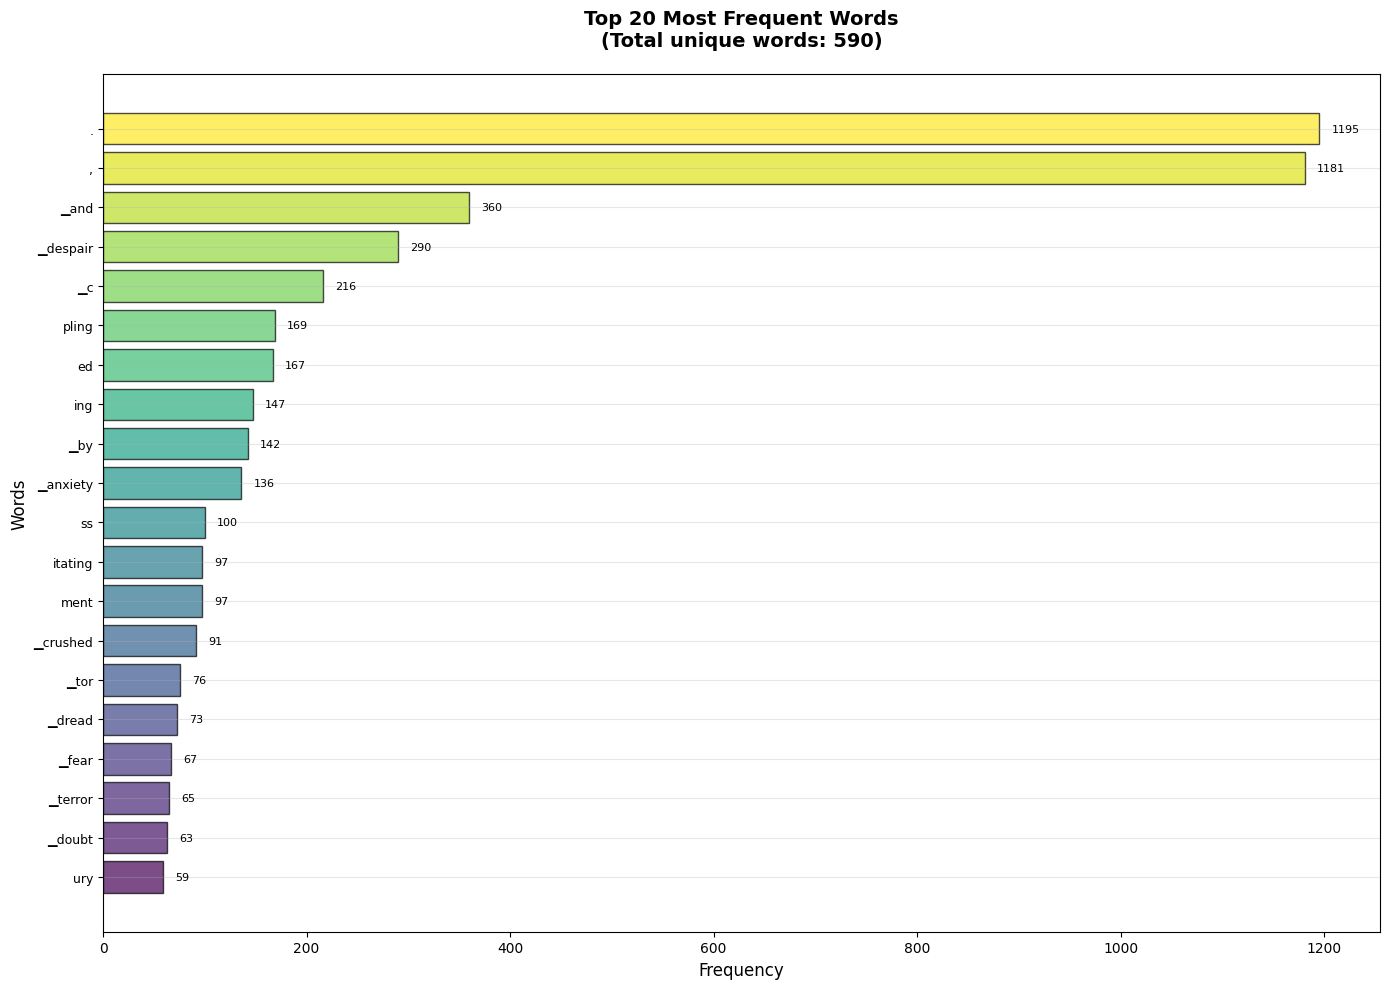

In [ ]:
print("\n=== Horizontal Bar Chart (Recommended for many words) ===")
# plot_top_words_horizontal(data3, top_n=20)
plot_top_words_enhanced(data1, top_n=20, horizontal=True)

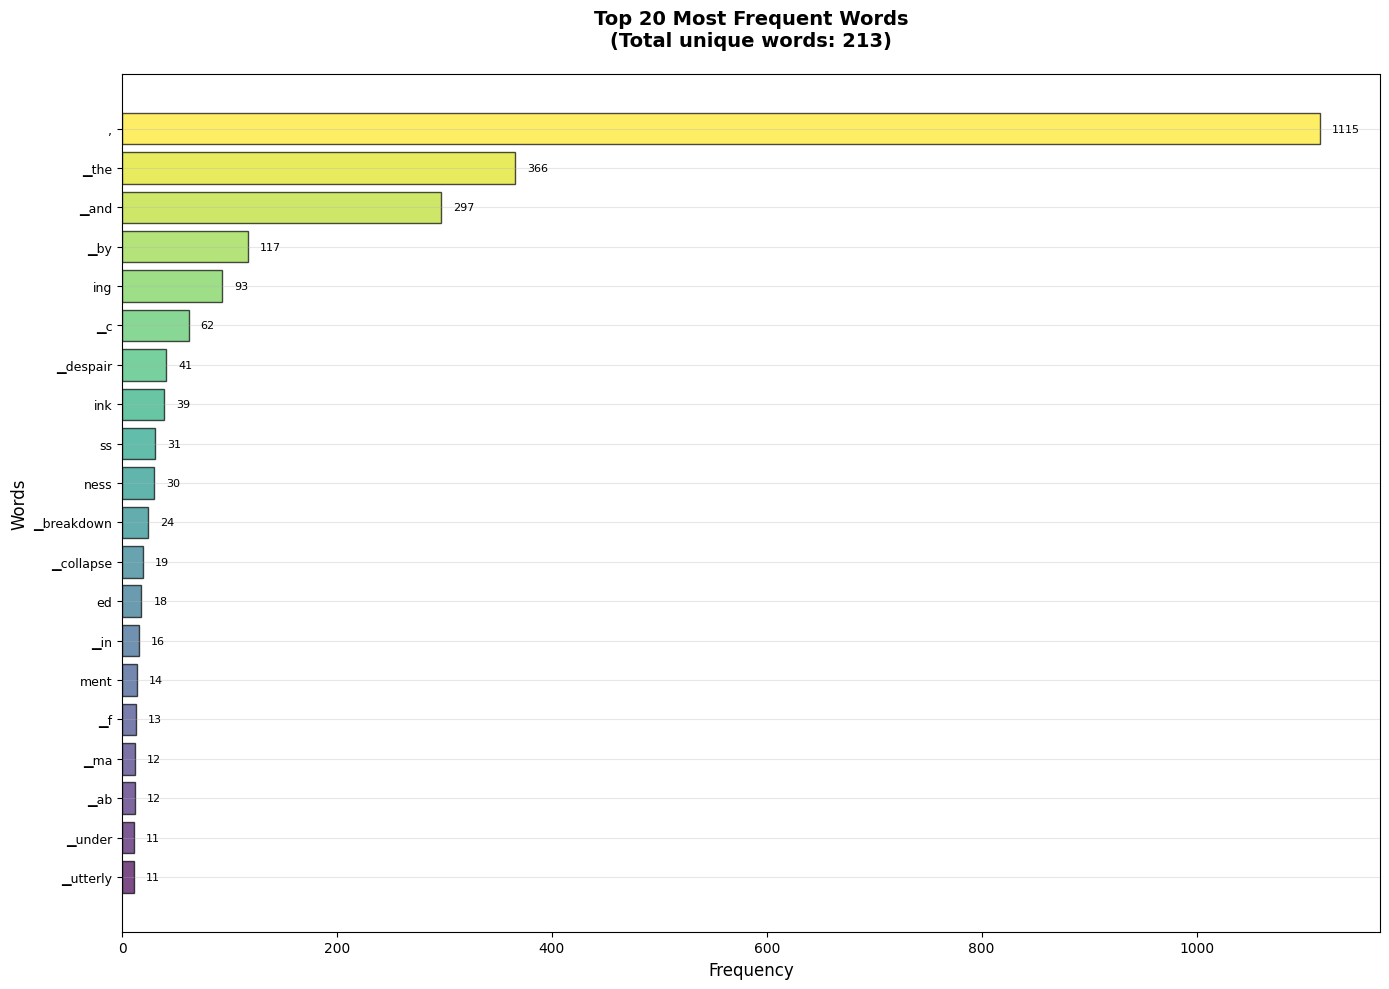

In [ ]:
plot_top_words_enhanced(data4, top_n=20, horizontal=True)

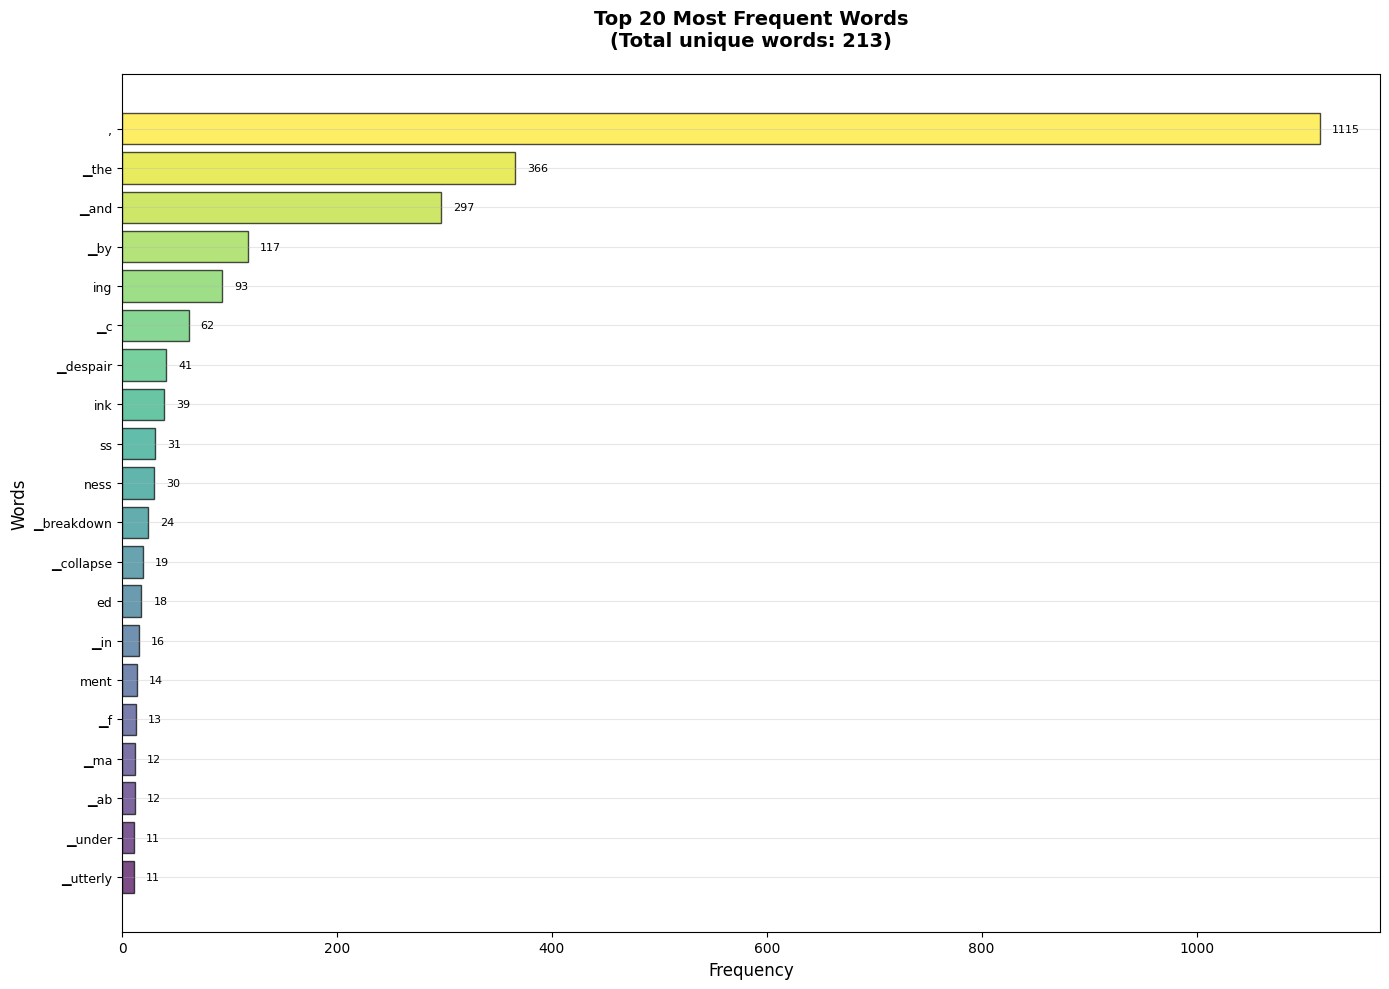

In [ ]:
plot_top_words_enhanced(data4, top_n=20, horizontal=True)

# NEW

In [ ]:
def plot_top_words_horizontal(list_of_lists, top_n=20, save_path='L1'):
    """
    Plot a horizontal bar chart of the top N most frequent words and save to PDF.
    """
    # Calculate word frequencies
    all_words = [word for sublist in list_of_lists for word in sublist]
    word_freq = Counter(all_words)

    # Get top N words
    top_words = word_freq.most_common(top_n)

    if not top_words:
        print("No words found to plot!")
        return

    # Separate words and frequencies (reverse order for horizontal chart)
    words, frequencies = zip(*top_words)
    words = words[::-1]
    frequencies = frequencies[::-1]

    # Create the plot
    plt.figure(figsize=(12, max(10, top_n * 0.3)))  # Adjust height based on number of words

    # Create horizontal bars
    bars = plt.barh(range(len(words)), frequencies, color='lightcoral', edgecolor='black', alpha=0.7)

    # Customize the plot
    plt.ylabel('Tokens', fontsize=12)
    plt.xlabel('Frequency', fontsize=12)
    plt.title(f'Top {top_n} Most Frequent Tokens', fontsize=14, fontweight='bold')
    plt.yticks(range(len(words)), words, fontsize=9)

    # Add value labels to the right of bars
    for i, bar in enumerate(bars):
        width = bar.get_width()
        plt.text(width + max(frequencies)*0.01, bar.get_y() + bar.get_height()/2.,
                f'{width}', ha='left', va='center', fontsize=8)

    # Add grid
    plt.grid(axis='x', alpha=0.3)

    # Adjust layout
    plt.tight_layout()

    # Save the plot if save_path is provided
    if save_path:
        plt.savefig(save_path, format='pdf', bbox_inches='tight', dpi=300)
        print(f"Plot saved as: {save_path}")

    plt.show()

    return len(top_words)

In [ ]:
def plot_top_words_enhanced(list_of_lists, top_n=20, horizontal=True, save_path='L1enhanced'):
    """
    Enhanced version with better styling and save to PDF functionality.
    """
    # Calculate word frequencies
    all_words = [word for sublist in list_of_lists for word in sublist]
    word_freq = Counter(all_words)

    # Get top N words
    top_words = word_freq.most_common(top_n)

    if not top_words:
        print("No words found to plot!")
        return

    # Separate words and frequencies
    words, frequencies = zip(*top_words)

    # Adjust figure size based on orientation and number of words
    if horizontal:
        fig, ax = plt.subplots(figsize=(14, max(10, top_n * 0.3)))
    else:
        fig, ax = plt.subplots(figsize=(16, 10))

    if horizontal:
        # Horizontal bar chart
        words = words[::-1]  # Reverse for descending order
        frequencies = frequencies[::-1]

        bars = ax.barh(range(len(words)), frequencies,
                      color=plt.cm.viridis(np.linspace(0, 1, len(words))),
                      edgecolor='black', alpha=0.7)

        ax.set_yticks(range(len(words)))
        ax.set_yticklabels(words, fontsize=12)
        ax.set_xlabel('Frequency', fontsize=12)
        ax.set_ylabel('Tokens', fontsize=12)

        # Add value labels
        for i, bar in enumerate(bars):
            width = bar.get_width()
            ax.text(width + max(frequencies)*0.01, bar.get_y() + bar.get_height()/2.,
                   f'{width}', ha='left', va='center', fontsize=12)
        ax.grid(True, alpha=0.3, axis='x')
    else:
        # Vertical bar chart
        bars = ax.bar(range(len(words)), frequencies,
                     color=plt.cm.plasma(np.linspace(0, 1, len(words))),
                     edgecolor='black', alpha=0.7)

        ax.set_xticks(range(len(words)))
        ax.set_xticklabels(words, rotation=45, ha='right', fontsize=12)
        ax.set_xlabel('Tokens', fontsize=12)
        ax.set_ylabel('Frequency', fontsize=12)

        # Add value labels
        for i, bar in enumerate(bars):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{height}', ha='center', va='bottom', fontsize=12, rotation=0)
        ax.grid(True, alpha=0.3, axis='y')

    ax.set_title(f'Top {top_n} Most Frequent Tokens\n(Total unique tokens: {len(word_freq)})',
                fontsize=14, fontweight='bold', pad=20)

    plt.tight_layout()

    # Save the plot if save_path is provided
    if save_path:
        plt.savefig(save_path, format='pdf', bbox_inches='tight', dpi=300)
        print(f"Plot saved as: {save_path}")

    plt.show()

    return len(top_words)

In [ ]:
# Main function to generate and save all plots
def generate_and_save_all_plots(list_of_lists, top_n=20, output_dir='word_frequency_plots'):
    """
    Generate and save all plots in PDF format.

    Args:
        list_of_lists: Your data
        top_n: Number of top words to display
        output_dir: Directory to save the plots
    """
    # Create output directory if it doesn't exist
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
        print(f"Created directory: {output_dir}")

    print("Generating plots...")

    # 1. Horizontal bar chart
    horizontal_path = os.path.join(output_dir, f'top_{top_n}_words_horizontal.pdf')
    print(f"\n1. Generating horizontal bar chart...")
    count1 = plot_top_words_horizontal(list_of_lists, top_n=top_n, save_path=horizontal_path)

    # 2. Enhanced horizontal chart
    enhanced_horizontal_path = os.path.join(output_dir, f'Ex_Newtop_{top_n}_enhanced_horizontalL4.pdf')
    print(f"\n2. Generating enhanced horizontal chart...")
    count2 = plot_top_words_enhanced(list_of_lists, top_n=top_n, horizontal=True,
                                   save_path=enhanced_horizontal_path)

    # 3. Enhanced vertical chart (optional - uncomment if you want this too)
    # enhanced_vertical_path = os.path.join(output_dir, f'top_{top_n}_words_enhanced_vertical.pdf')
    # print(f"\n3. Generating enhanced vertical chart...")
    # count3 = plot_top_words_enhanced(list_of_lists, top_n=top_n, horizontal=False,
    #                                save_path=enhanced_vertical_path)

    print(f"\n=== Plot Generation Complete ===")
    print(f"Plots saved in directory: {output_dir}")
    print(f"Files created:")
    print(f"  - {os.path.basename(horizontal_path)}")
    print(f"  - {os.path.basename(enhanced_horizontal_path)}")
    # print(f"  - {os.path.basename(enhanced_vertical_path)}")  # Uncomment if using vertical

    return {
        'horizontal_path': horizontal_path,
        'enhanced_horizontal_path': enhanced_horizontal_path,
        # 'enhanced_vertical_path': enhanced_vertical_path  # Uncomment if using vertical
    }

Generating plots...

1. Generating horizontal bar chart...
Plot saved as: word_frequency_plots/top_20_words_horizontal.pdf


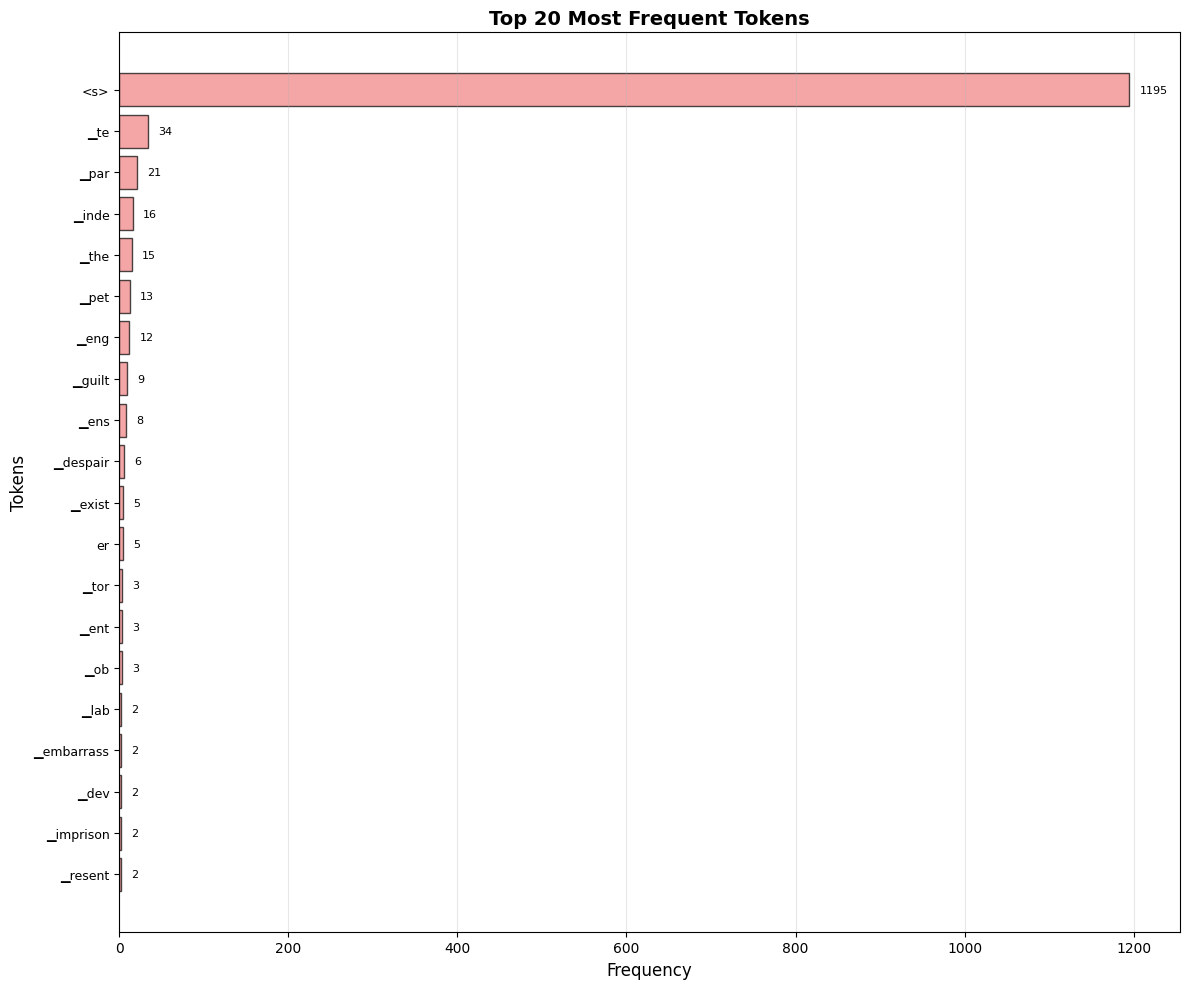


2. Generating enhanced horizontal chart...
Plot saved as: word_frequency_plots/Ex_Newtop_20_enhanced_horizontalL4.pdf


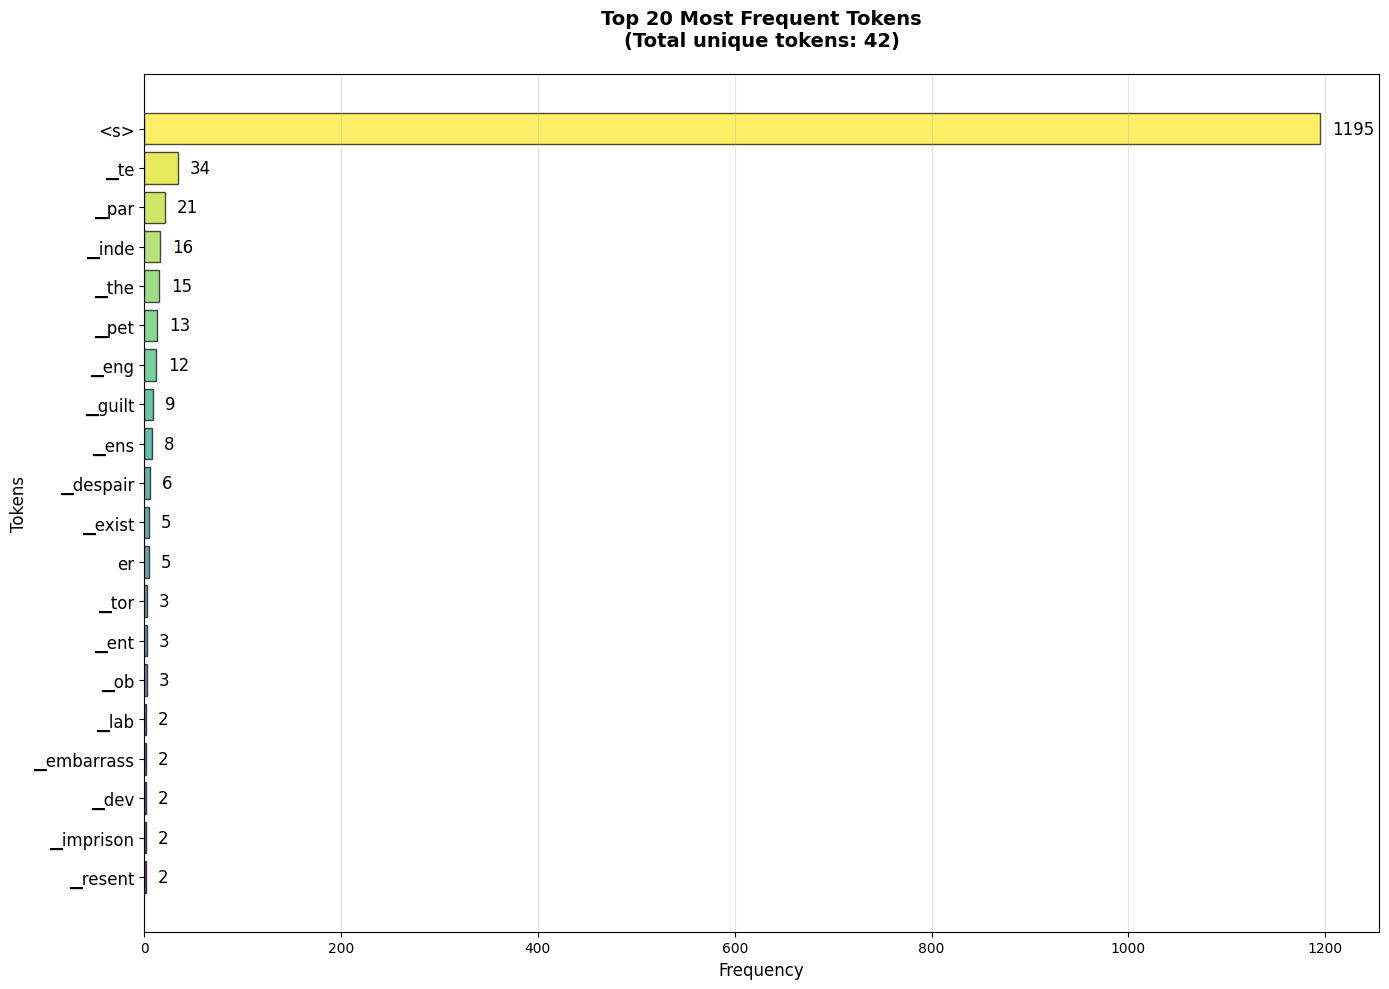


=== Plot Generation Complete ===
Plots saved in directory: word_frequency_plots
Files created:
  - top_20_words_horizontal.pdf
  - Ex_Newtop_20_enhanced_horizontalL4.pdf


In [ ]:
# Generate and save all plots (using top_n=10 for demo)
saved_files = generate_and_save_all_plots(data4, top_n=20)

# If you want to generate just one plot:
# plot_top_words_horizontal(lists_of_words, top_n=100, save_path='my_plot.pdf')

Four plots together

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image
import fitz  # PyMuPDF

In [ ]:
from io import BytesIO

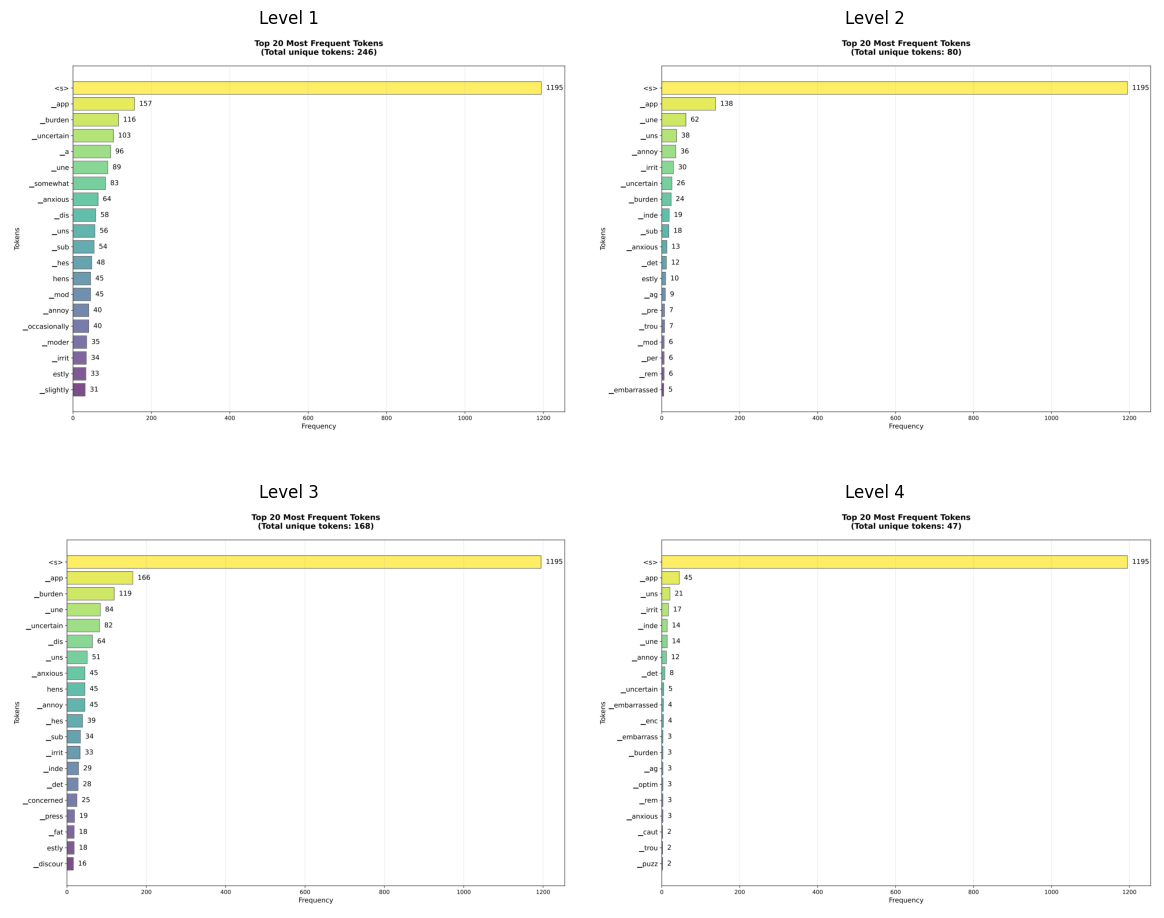

Combined plots saved as: four_plots_2x2_grid.pdf


In [ ]:
def pdf_to_image(pdf_path, dpi=150):
    """Convert PDF page to PIL Image"""
    pdf_document = fitz.open(pdf_path)
    page = pdf_document.load_page(0)

    # Convert to image with specified DPI
    mat = fitz.Matrix(dpi/72, dpi/72)  # 72 is the default PDF DPI
    pix = page.get_pixmap(matrix=mat)
    img_data = pix.tobytes("png")

    pdf_document.close()
    return Image.open(BytesIO(img_data))

def combine_pdfs_to_grid(pdf_files, output_path='combined_plots.pdf', dpi=150):
    """Combine multiple PDF plots into a 2x2 grid"""

    # Convert PDFs to images
    images = [pdf_to_image(pdf_file, dpi) for pdf_file in pdf_files]

    # Create figure with 2x2 subplots
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    axes = axes.flatten()

    # Display each image in its subplot
    for ax, img, title in zip(axes, images, ['Level 1', 'Level 2', 'Level 3', 'Level 4']):
        ax.imshow(img)
        ax.axis('off')  # Remove axes
        ax.set_title(title, fontsize=12, pad=10)

    # Adjust layout
    plt.tight_layout(pad=2.0)

    # Save as PDF
    plt.savefig(output_path, format='pdf', bbox_inches='tight', dpi=300)
    plt.show()

    print(f"Combined plots saved as: {output_path}")

# List of your PDF files
pdf_files = ['Mo_Newtop_20_enhanced_horizontalL1.pdf', 'Mo_Newtop_20_enhanced_horizontalL2.pdf', 'Mo_Newtop_20_enhanced_horizontalL3.pdf', 'Mo_Newtop_20_enhanced_horizontalL4.pdf']

# Combine them into a 2x2 grid
combine_pdfs_to_grid(pdf_files, 'four_plots_2x2_grid.pdf')

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import fitz
from io import BytesIO

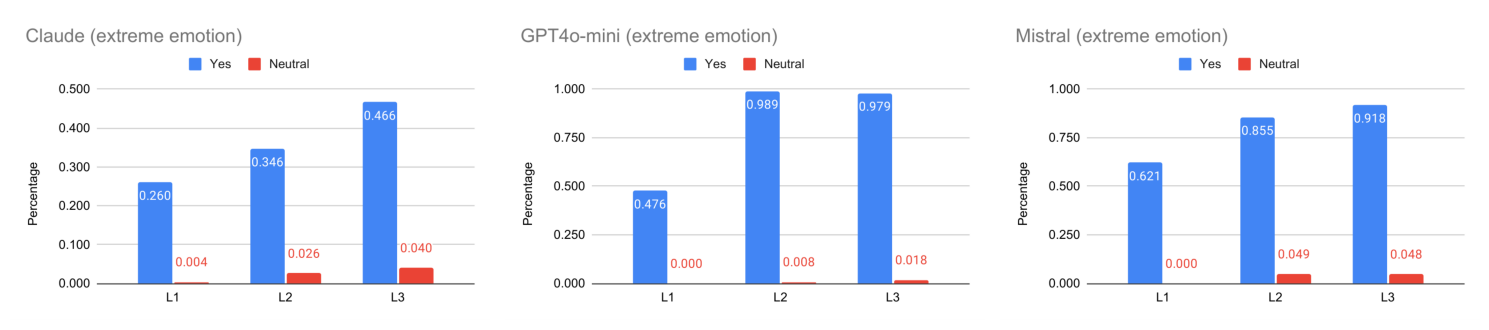

Three plots in a row saved as: three_plots_side_by_side.pdf


In [ ]:
def combine_3_pdfs_row(pdf_files, output_path='three_plots_row.pdf', dpi=150):
    """Combine 3 PDFs into a single row"""

    # Convert PDFs to images
    images = []
    for pdf_file in pdf_files:
        pdf_document = fitz.open(pdf_file)
        page = pdf_document.load_page(0)
        mat = fitz.Matrix(dpi/72, dpi/72)
        pix = page.get_pixmap(matrix=mat)
        img_data = pix.tobytes("png")
        images.append(Image.open(BytesIO(img_data)))
        pdf_document.close()

    # Create figure with 1x3 subplots (wider to accommodate three plots)
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Display images
    for ax, img in zip(axes, images):
        ax.imshow(img)
        ax.axis('off')  # Remove axes

    # Adjust layout to minimize white space
    plt.subplots_adjust(wspace=0.05, left=0.05, right=0.95, top=0.95, bottom=0.05)
    plt.tight_layout()

    # Save as PDF
    plt.savefig(output_path, format='pdf', bbox_inches='tight', dpi=300)
    plt.show()
    print(f"Three plots in a row saved as: {output_path}")

# Usage
pdf_files = ['Claude (extreme emotion).pdf', 'GPT4o-mini (extreme emotion).pdf', 'Mistral (extreme emotion).pdf']
combine_3_pdfs_row(pdf_files, 'three_plots_side_by_side.pdf')

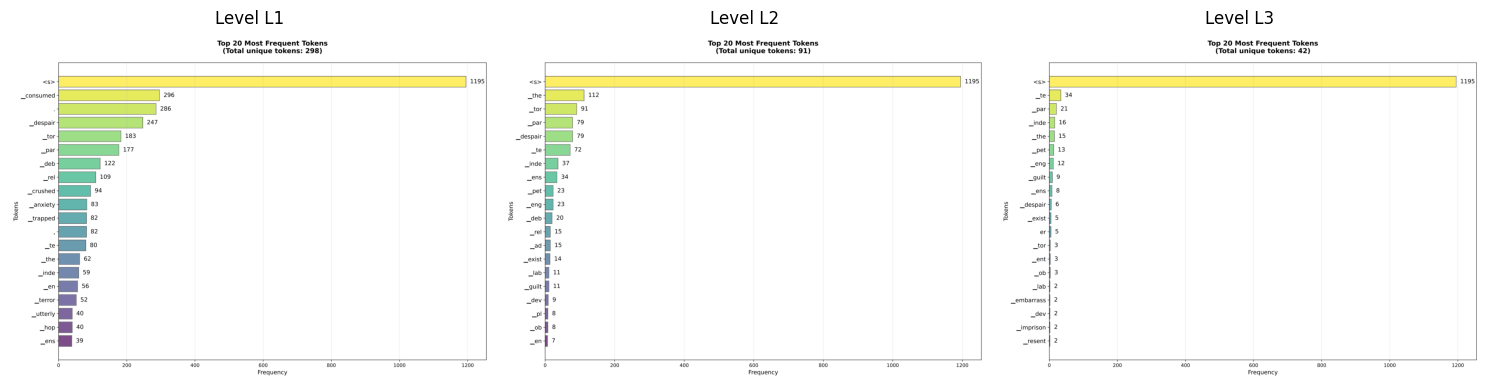

Three plots in a row saved as: three_plots_with_titles.pdf


In [ ]:
def combine_3_pdfs_customizable(pdf_files, output_path='three_plots_row.pdf',
                               figsize=(15, 5), dpi=150, wspace=0.05,
                               add_titles=False, titles=None):
    """Combine 3 PDFs in a row with customizable options"""

    if titles is None:
        titles = [f'Plot {i+1}' for i in range(len(pdf_files))]

    # Convert PDFs to images
    images = []
    for pdf_file in pdf_files:
        pdf_document = fitz.open(pdf_file)
        page = pdf_document.load_page(0)
        mat = fitz.Matrix(dpi/72, dpi/72)
        pix = page.get_pixmap(matrix=mat)
        img_data = pix.tobytes("png")
        images.append(Image.open(BytesIO(img_data)))
        pdf_document.close()

    # Create figure with 1x3 subplots
    fig, axes = plt.subplots(1, 3, figsize=figsize)

    # Display images
    for i, (ax, img) in enumerate(zip(axes, images)):
        ax.imshow(img)
        ax.axis('off')
        if add_titles:
            ax.set_title(titles[i], fontsize=12, pad=10)

    # Adjust spacing
    plt.subplots_adjust(wspace=wspace)
    plt.tight_layout()

    # Save as PDF
    plt.savefig(output_path, format='pdf', bbox_inches='tight', dpi=300)
    plt.show()
    print(f"Three plots in a row saved as: {output_path}")

# Usage examples
pdf_files = ['Claude (moderate emotion).pdf', 'GPT4o-mini (moderate emotion).pdf', 'Mistral (moderate emotion).pdf']

# Option 1: Clean version without titles
# combine_3_pdfs_customizable(pdf_files, 'three_plots_clean.pdf')

# Option 2: With titles
combine_3_pdfs_customizable(pdf_files, 'three_plots_with_titles.pdf',
                           add_titles=True,
                           titles=['Level L1', 'Level L2', 'Level L3'])

# Option 3: Custom size
# combine_3_pdfs_customizable(pdf_files, 'three_plots_custom.pdf',
#                            figsize=(18, 4), wspace=0.02)

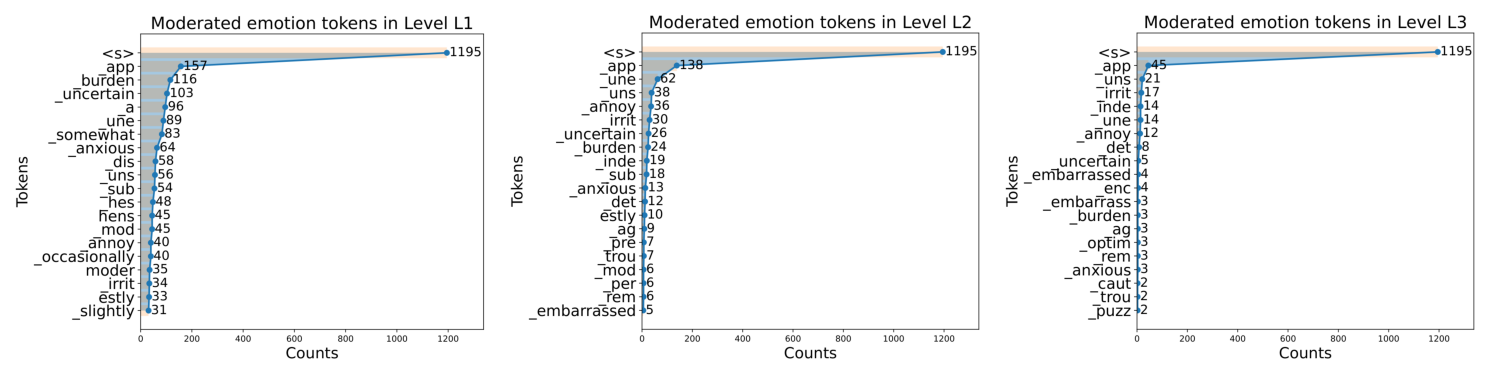

Three plots in a row saved as: three_plots_with_titlesMod.pdf


In [ ]:
def combine_3_pdfs_customizable(pdf_files, output_path='three_plots_row.pdf',
                               figsize=(15, 5), dpi=150, wspace=0.05,
                               add_titles=False, titles=None):
    """Combine 3 PDFs in a row with customizable options"""

    if titles is None:
        titles = [f'Plot {i+1}' for i in range(len(pdf_files))]

    # Convert PDFs to images
    images = []
    for pdf_file in pdf_files:
        pdf_document = fitz.open(pdf_file)
        page = pdf_document.load_page(0)
        mat = fitz.Matrix(dpi/72, dpi/72)
        pix = page.get_pixmap(matrix=mat)
        img_data = pix.tobytes("png")
        images.append(Image.open(BytesIO(img_data)))
        pdf_document.close()

    # Create figure with 1x3 subplots
    fig, axes = plt.subplots(1, 3, figsize=figsize)

    # Display images
    for i, (ax, img) in enumerate(zip(axes, images)):
        ax.imshow(img)
        ax.axis('off')
        if add_titles:
            ax.set_title(titles[i], fontsize=12, pad=10)

    # Adjust spacing
    plt.subplots_adjust(wspace=wspace)
    plt.tight_layout()

    # Save as PDF
    plt.savefig(output_path, format='pdf', bbox_inches='tight', dpi=300)
    plt.show()
    print(f"Three plots in a row saved as: {output_path}")

# Usage examples
pdf_files = ['Moderated_Level_L1.pdf', 'Moderated_Level_L2.pdf', 'Moderated_Level_L3.pdf']  #Claude (moderate emotion), GPT4o-mini (moderate emotion), Mistral (moderate emotion)

# Option 1: Clean version without titles
# combine_3_pdfs_customizable(pdf_files, 'three_plots_clean.pdf')

# Option 2: With titles
combine_3_pdfs_customizable(pdf_files, 'three_plots_with_titlesMod.pdf',
                           add_titles=False)  #,titles=['Level L1', 'Level L2', 'Level L3'], True

# Option 3: Custom size
# combine_3_pdfs_customizable(pdf_files, 'three_plots_custom.pdf',
#                            figsize=(18, 4), wspace=0.02)

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('Inli_ML_responseRWCoT.csv') #Data_implicature_2
df.head(2)

,Unnamed: 0,Premise,Hypothesis,Answer_Aneesh,Answer,claude_response1,Elsy Mam,state,ML_predicted
0,0,When it's a fog filled day and the depression ...,"The speaker is having a clear, peaceful week a...",Definitely false,Definitely false,1,Definitely false,True,Definitely true
1,1,In this show I watch the main character said s...,The speaker has always been a winner and is ab...,Definitely false,Definitely false,0,Definitely false,True,Definitely false


In [ ]:
df['ML_predicted'].value_counts()

,count
ML_predicted,
Definitely true,1296
Definitely false,82
Might be true,19


In [ ]:
df1 = pd.read_csv('Inli_ML_responseRWKS.csv') #Data_implicature_2
# df.head(2)
df1['ML_predicted'].value_counts()

,count
ML_predicted,
Definitely true,1120
Definitely false,268
Might be true,9


In [ ]:
df2 = pd.read_csv('Inli_ML_responseRWZS.csv') #Data_implicature_2
df.head(2)
# df2['ML_predicted'].value_counts()

,Unnamed: 0,Premise,Hypothesis,Answer_Aneesh,Answer,claude_response1,Elsy Mam,state,ML_predicted
0,0,When it's a fog filled day and the depression ...,"The speaker is having a clear, peaceful week a...",Definitely false,Definitely false,1,Definitely false,True,Definitely true
1,1,In this show I watch the main character said s...,The speaker has always been a winner and is ab...,Definitely false,Definitely false,0,Definitely false,True,Definitely false


In [ ]:
df2['ML_predicted'].value_counts()

,count
ML_predicted,


# Four plots

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image
import fitz  # PyMuPDF

In [ ]:
from io import BytesIO

In [ ]:
def pdf_to_image(pdf_path, dpi=150):
    """Convert PDF page to PIL Image"""
    pdf_document = fitz.open(pdf_path)
    page = pdf_document.load_page(0)

    # Convert to image with specified DPI
    mat = fitz.Matrix(dpi/72, dpi/72)  # 72 is the default PDF DPI
    pix = page.get_pixmap(matrix=mat)
    img_data = pix.tobytes("png")

    pdf_document.close()
    return Image.open(BytesIO(img_data))

def combine_pdfs_to_grid(pdf_files, output_path='combined_plots.pdf', dpi=150):
    """Combine multiple PDF plots into a 2x2 grid"""

    # Convert PDFs to images
    images = [pdf_to_image(pdf_file, dpi) for pdf_file in pdf_files]

    # Create figure with 2x2 subplots
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    axes = axes.flatten()

    # Display each image in its subplot
    for ax, img, title in zip(axes, images, ['Level 1', 'Level 2', 'Level 3', 'Level 4']):
        ax.imshow(img)
        ax.axis('off')  # Remove axes
        ax.set_title(title, fontsize=12, pad=10)

    # Adjust layout
    plt.tight_layout(pad=2.0)

    # Save as PDF
    plt.savefig(output_path, format='pdf', bbox_inches='tight', dpi=300)
    plt.show()

    print(f"Combined plots saved as: {output_path}")

# List of your PDF files
pdf_files = ['Hindi2Marathi(BLEUscores).pdf', 'Hindi2Marathi(ChRF++scores).pdf', 'Marathi2Hindi(BLEU-scores).pdf', 'Marathi2Hindi(ChRF++scores).pdf']

# Combine them into a 2x2 grid
combine_pdfs_to_grid(pdf_files, 'BERT.pdf')

AttributeError: module 'fitz' has no attribute 'open'

false

In [ ]:
500-400

100

true

In [ ]:
497-400

97

MB true

In [ ]:
400-350

50

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df1 = pd.read_csv('Data_presupposition_2.csv')
df2 = pd.read_csv('Data_implicature_2.csv')

In [ ]:
df1['Answer'].value_counts()

,count
Answer,
Definitely true,497
Definitely false,494
Might be true,401


In [ ]:
df2['Answer'].value_counts()

,count
Answer,
Definitely false,500
Definitely true,497
Might be true,400


In [ ]:
from PyPDF2 import PdfReader, PdfWriter, PageObject
from reportlab.pdfgen import canvas
from reportlab.lib.pagesizes import letter
import io
from PyPDF2.Transformation import Transformation

# Paths to the input PDFs
pdf1_path = 'Extreme emotion (Claude).pdf'
pdf2_path = 'Moderated emotion (Claude).pdf'
output_pdf_path = 'combined_side_by_side.pdf'

# Read both PDFs
reader1 = PdfReader(pdf1_path)
reader2 = PdfReader(pdf2_path)

# Create a new PDF writer
writer = PdfWriter()

# Get the first page from each PDF
page1 = reader1.pages[0]
page2 = reader2.pages[0]

# Create a new page that is wide enough to fit both pages side by side
width = page1.mediabox.width + page2.mediabox.width
height = max(page1.mediabox.height, page2.mediabox.height)

# Create a blank page with the new dimensions
new_page = PageObject.create_blank_page(width=width, height=height)

# Merge the first PDF page on the left
new_page.merge_page(page1)

# Merge the second PDF page on the right by shifting it to the right by width of page1
# Use merge_page with a translation transformation
translation = Transformation().translate(tx=page1.mediabox.width, ty=0)
new_page.merge_page(page2, translation)


# Add the new page to the writer
writer.add_page(new_page)

# Write the output PDF
with open(output_pdf_path, 'wb') as f_out:
    writer.write(f_out)

print(f"Combined PDF saved as {output_pdf_path}")

ModuleNotFoundError: No module named 'PyPDF2.Transformation'

In [ ]:
from PyPDF2 import PdfReader, PdfWriter, PageObject

pdf1_path = 'Extreme emotion (GPT4o-mini).pdf'
pdf2_path = 'Moderated emotion (GPT4o-mini).pdf'
output_pdf_path = 'combined_side_by_side.pdf'
# Input PDFs

# Load PDFs
reader1 = PdfReader(pdf1_path)
reader2 = PdfReader(pdf2_path)

# Writer for final output
writer = PdfWriter()

# Take first page from each
page1 = reader1.pages[0]
page2 = reader2.pages[0]

# New page dimensions = sum of widths, max of heights
width = float(page1.mediabox.width) + float(page2.mediabox.width)
height = max(float(page1.mediabox.height), float(page2.mediabox.height))

# Create blank page
new_page = PageObject.create_blank_page(width=width, height=height)

# Merge first page (left side)
new_page.merge_page(page1)

# Merge second page (shifted to the right)
page2.translate(tx=float(page1.mediabox.width), ty=0)
new_page.merge_page(page2)

# Add new page
writer.add_page(new_page)

# Save combined PDF
with open(output_pdf_path, "wb") as f_out:
    writer.write(f_out)

print(f"✅ Combined PDF saved as {output_pdf_path}")

AttributeError: 'PageObject' object has no attribute 'translate'

After running the cell above, you can download the combined PDF using the link below.

In [ ]:
import fitz

from PyPDF2 import PdfReader, PdfWriter, PageObject

pdf1_path = 'Extreme emotion.pdf' # (GPT4o-mini)
pdf2_path = 'Moderated emotion.pdf'  # (GPT4o-mini)
output_pdf_path = 'combined_side_by_side.pdf'

In [ ]:
#install PyMuPDF  #pip install pymupdf
import fitz  # PyMuPDF

def combine_pdfs_side_by_side_pymupdf(pdf1_path, pdf2_path, out_path):
    # open docs
    doc1 = fitz.open(pdf1_path)
    doc2 = fitz.open(pdf2_path)

    # pick pages (0 = first). modify if you want different pages or loop.
    p1 = doc1.load_page(0)
    p2 = doc2.load_page(0)

    r1 = p1.rect  # rectangle (x0,y0,x1,y1) for page1
    r2 = p2.rect

    new_width = r1.width + r2.width
    new_height = max(r1.height, r2.height)

    # create output PDF and new page with combined size
    new_doc = fitz.open()
    new_page = new_doc.new_page(width=new_width, height=new_height)

    # place page1 at x=0, aligned to bottom
    new_page.show_pdf_page(
        fitz.Rect(0, new_height - r1.height, r1.width, new_height),
        doc1, 0
    )

    # place page2 to the right of page1, aligned to bottom
    new_page.show_pdf_page(
        fitz.Rect(r1.width, new_height - r2.height, new_width, new_height),
        doc2, 0
    )

    # save and close
    new_doc.save(out_path)
    new_doc.close()
    doc1.close()
    doc2.close()
    print("Saved:", out_path)


# Example usage
# combine_pdfs_side_by_side_pymupdf("image1.pdf", "image2.pdf", "combined_side_by_side.pdf")
combine_pdfs_side_by_side_pymupdf(pdf1_path, pdf2_path, output_pdf_path)

Saved: combined_side_by_side.pdf


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import requests
from io import BytesIO
from PIL import Image
import fitz  # PyMuPDF

def download_and_convert_pdf(url):
    """Download PDF and convert to image"""
    response = requests.get(url)
    pdf_data = BytesIO(response.content)

    # Open PDF with PyMuPDF
    pdf_document = fitz.open(stream=pdf_data, filetype="pdf")

    # Convert first page to image
    page = pdf_document.load_page(0)
    pix = page.get_pixmap(matrix=fitz.Matrix(2, 2))  # Higher resolution
    img_data = pix.tobytes("png")

    return Image.open(BytesIO(img_data))

# URLs of your PDF images (replace with actual URLs)
pdf_urls = [
    "https://drive.google.com/file/d/1txI-tkJE8vEhFvRbksl_CU9qRl3nfpm5/view?usp=sharing",
    "https://drive.google.com/file/d/18L1ZLikTiP9czaSMMRjjrbVmeNc3HFej/view?usp=sharing"
]

# Download and convert PDFs to images
images = [download_and_convert_pdf(url) for url in pdf_urls]

# Create a figure with two subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Display images
for i, (ax, img) in enumerate(zip(axes, images)):
    ax.imshow(img)
    ax.axis('off')  # Hide axes
    ax.set_title(f'Figure {i+1}', fontsize=14)

plt.tight_layout()
plt.savefig('side_by_side_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

ModuleNotFoundError: No module named 'fitz'

In [ ]:
#https://drive.google.com/file/d/1txI-tkJE8vEhFvRbksl_CU9qRl3nfpm5/view?usp=sharing
#https://drive.google.com/file/d/18L1ZLikTiP9czaSMMRjjrbVmeNc3HFej/view?usp=sharing

In [ ]:
from IPython.display import FileLink
FileLink('combined_side_by_side.pdf')

In [ ]:
from IPython.display import FileLink

# Provide a link to download the image
FileLink(output_pdf_path)

/content/combined_image.png

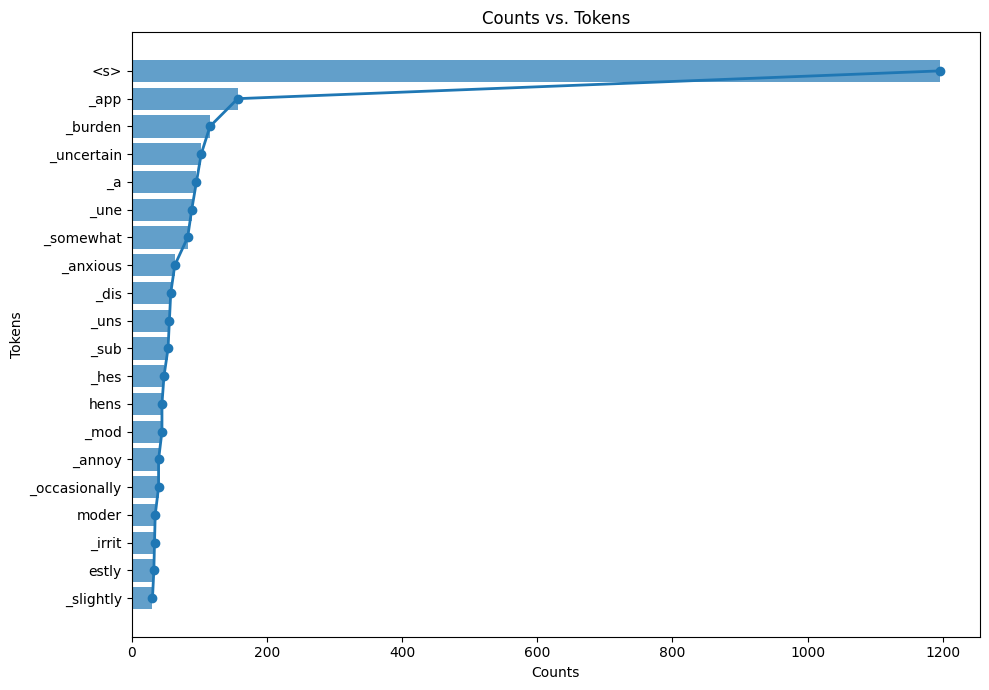

In [ ]:
import matplotlib.pyplot as plt

tokens = [
    "<s>", "_app", "_burden", "_uncertain", "_a", "_une",
    "_somewhat", "_anxious", "_dis", "_uns", "_sub", "_hes",
    "hens", "_mod", "_annoy", "_occasionally", "moder", "_irrit",
    "estly", "_slightly"
]

counts = [
    1195, 157, 116, 103, 96, 89, 83, 64, 58, 56,
    54, 48, 45, 45, 40, 40, 35, 34, 33, 31
]

fig, ax = plt.subplots(figsize=(10, 7))

# Horizontal bars
y = range(len(tokens))
ax.barh(y, counts, alpha=0.7)

# Line connecting the tips of the bars
ax.plot(counts, y, marker='o', linewidth=2)

# Labels
ax.set_yticks(y)
ax.set_yticklabels(tokens)
ax.set_xlabel("Counts")
ax.set_ylabel("Tokens")
ax.set_title("Counts vs. Tokens")

# Put the most frequent token at the top
ax.invert_yaxis()

plt.tight_layout()
plt.show()

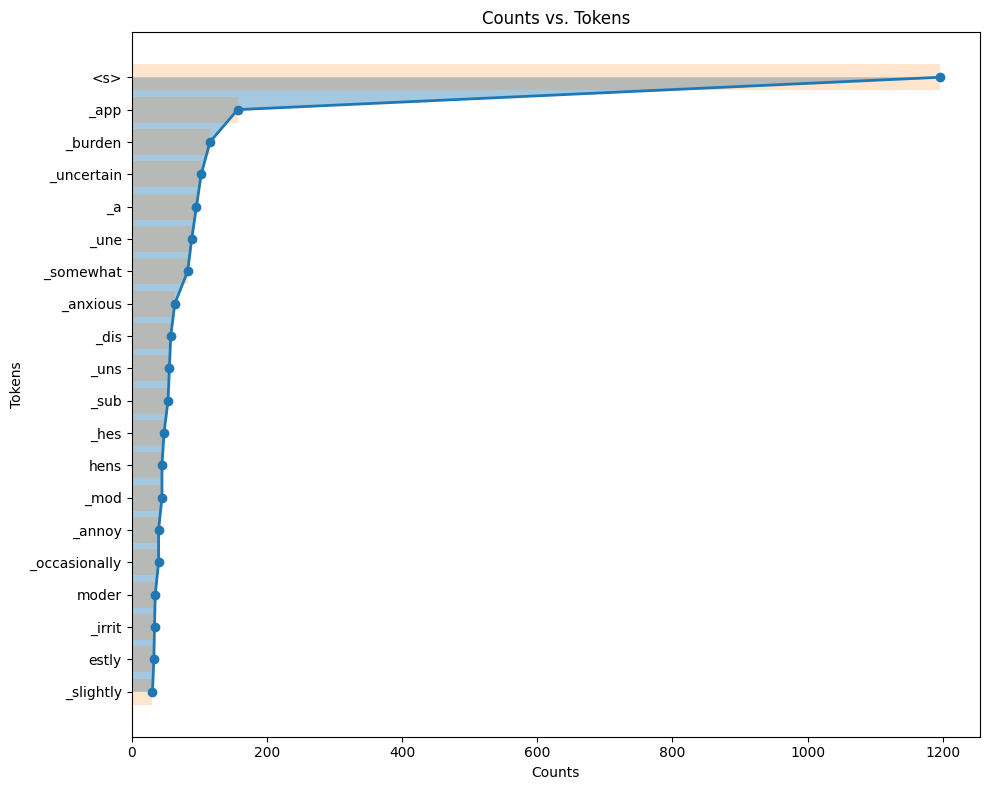

In [ ]:
# import matplotlib.pyplot as plt

tokens = [
    "<s>", "_app", "_burden", "_uncertain", "_a", "_une",
    "_somewhat", "_anxious", "_dis", "_uns", "_sub", "_hes",
    "hens", "_mod", "_annoy", "_occasionally", "moder", "_irrit",
    "estly", "_slightly"
]

counts = [
    1195, 157, 116, 103, 96, 89, 83, 64, 58, 56,
    54, 48, 45, 45, 40, 40, 35, 34, 33, 31
]

fig, ax = plt.subplots(figsize=(10, 8))

y = range(len(tokens))

# Filled horizontal "area"
ax.fill_betweenx(
    y,
    0,
    counts,
    alpha=0.4
)

# Line connecting the tips of the horizontal areas
ax.plot(
    counts,
    y,
    marker='o',
    linewidth=2
)

# Optional: thin horizontal bars underneath
ax.barh(
    y,
    counts,
    alpha=0.2
)

# Axis labels
ax.set_yticks(y)
ax.set_yticklabels(tokens)
ax.set_xlabel("Counts")
ax.set_ylabel("Tokens")
ax.set_title("Moderated Level L1") #Counts vs. Tokens

# Highest count at the top
ax.invert_yaxis()

plt.tight_layout()
plt.show()

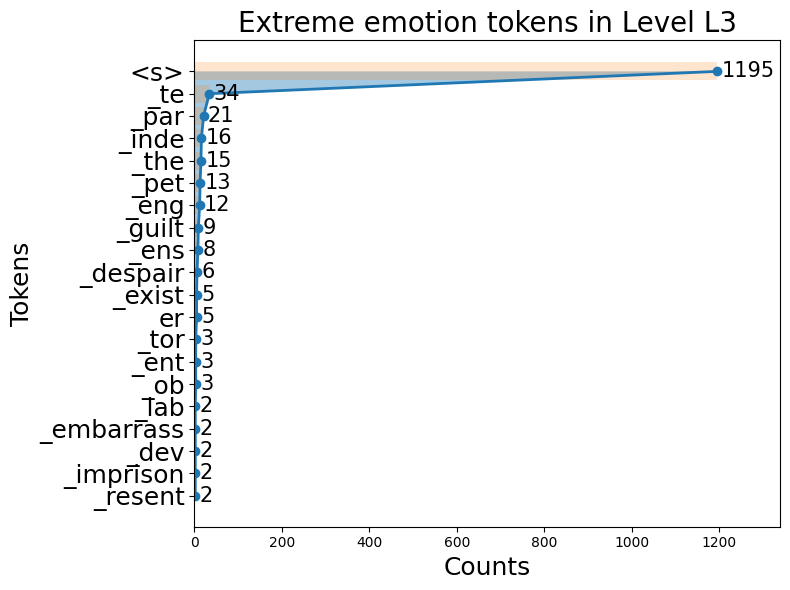

In [ ]:
# import matplotlib.pyplot as plt

tokens = [
    "<s>", "_te", "_par", "_inde", "_the", "_pet",
    "_eng", "_guilt", "_ens", "_despair", "_exist", "er",
    "_tor", "_ent", "_ob", "_lab", "_embarrass", "_dev",
    "_imprison", "_resent"
]

counts = [
    1195, 34, 21, 16, 15, 13, 12, 9, 8, 6,
    5, 5, 3, 3, 3, 2, 2, 2, 2, 2
]

# --------------------------------------------------
# Font-size controls
# --------------------------------------------------

TICK_FONT_SIZE = 18       # Token names on y-axis
AXIS_LABEL_SIZE = 18      # "Counts" and "Tokens"
TITLE_FONT_SIZE = 20      # Plot title
DATA_LABEL_SIZE = 15      # Numbers at the end of bars


fig, ax = plt.subplots(figsize=(8, 6))

y = range(len(tokens))

# Filled horizontal "area"
ax.fill_betweenx(
    y,
    0,
    counts,
    alpha=0.4
)

# Line connecting the tips of the horizontal areas
ax.plot(
    counts,
    y,
    marker='o',
    linewidth=2
)

# Horizontal bars underneath
ax.barh(
    y,
    counts,
    alpha=0.2
)

# --------------------------------------------------
# Data labels
# --------------------------------------------------

for i, count in enumerate(counts):
    ax.text(
        count + 10,       # Position slightly to the right of bar
        i,                # Vertical position
        str(count),       # Label
        va='center',
        fontsize=DATA_LABEL_SIZE
    )

# --------------------------------------------------
# Axis labels and title
# --------------------------------------------------

ax.set_yticks(y)
ax.set_yticklabels(tokens, fontsize=TICK_FONT_SIZE)

ax.set_xlabel(
    "Counts",
    fontsize=AXIS_LABEL_SIZE
)

ax.set_ylabel(
    "Tokens",
    fontsize=AXIS_LABEL_SIZE
)

ax.set_title(
    "Extreme emotion tokens in Level L3", #Counts vs. Tokens
    fontsize=TITLE_FONT_SIZE
)

# Put the most frequent token at the top
ax.invert_yaxis()

# Make sure there is enough space for the data labels
ax.set_xlim(0, max(counts) * 1.12)

plt.tight_layout()

plt.savefig("Extreme_Level_L3.pdf", format="pdf", bbox_inches="tight")
plt.show()

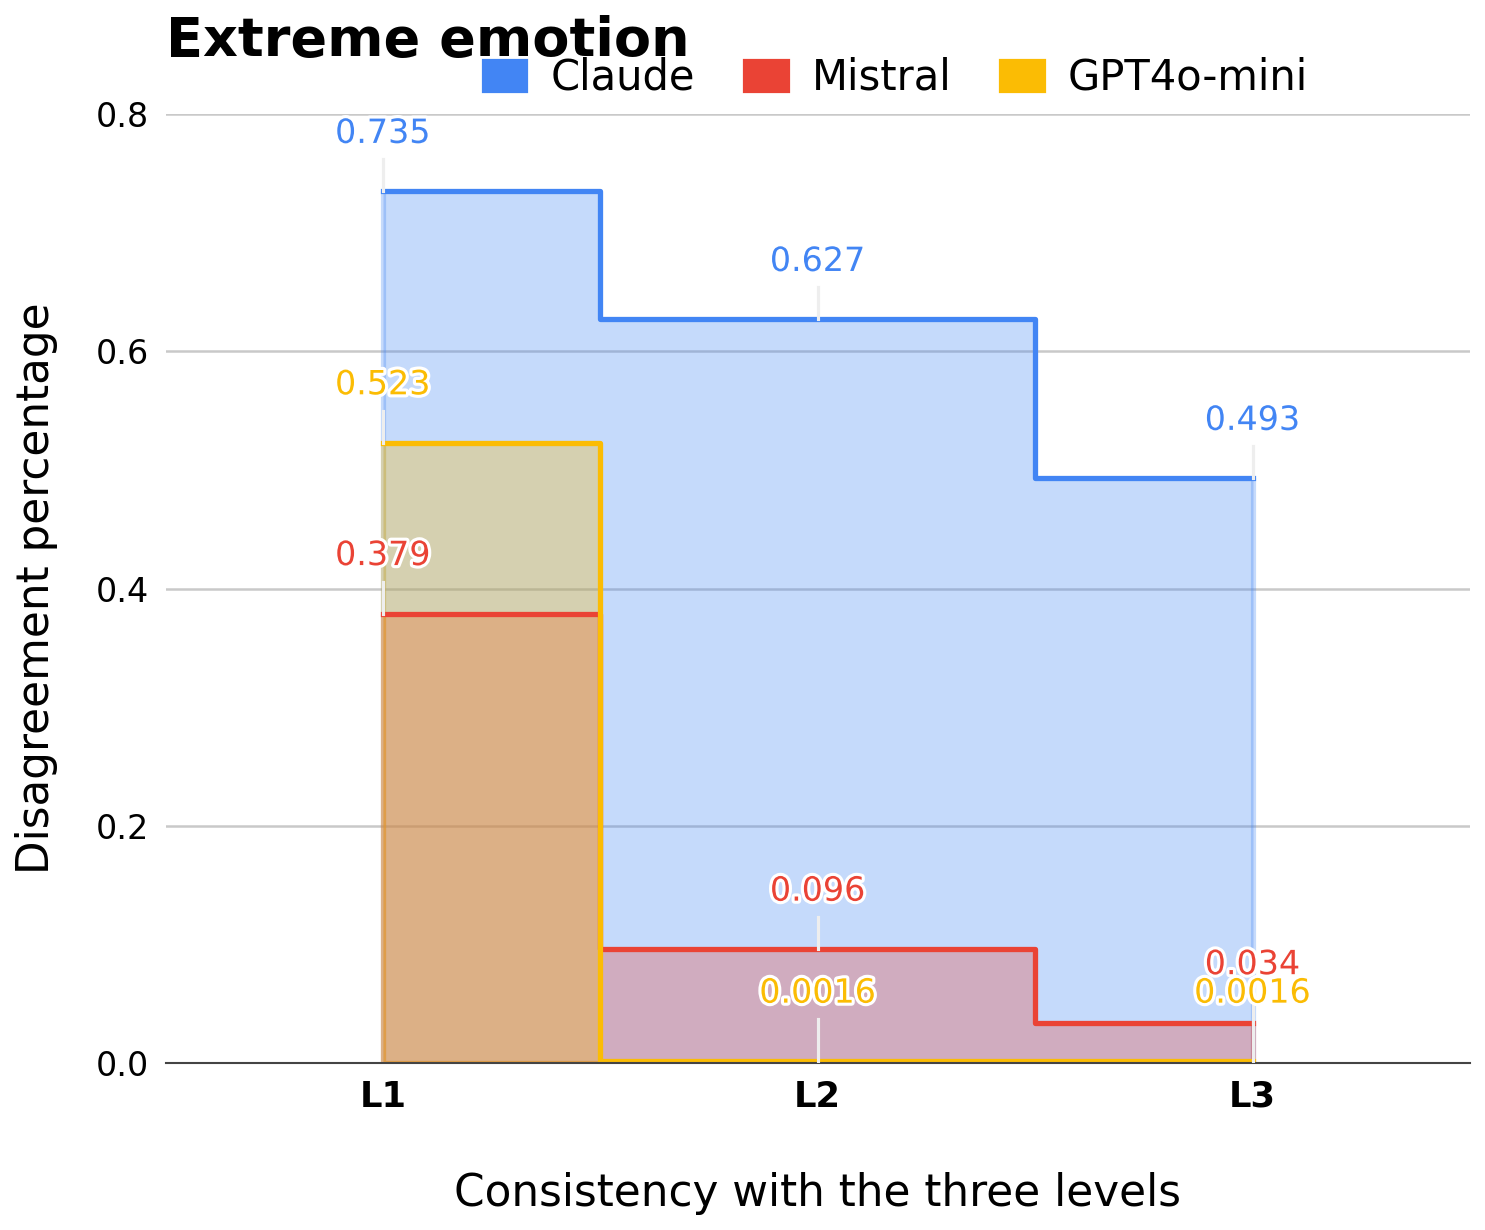

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

# ---------------------------------------------------------
# Data from Extreme_emotion.xlsx
# ---------------------------------------------------------

levels = ["L1", "L2", "L3"]

claude = np.array([0.735, 0.627, 0.493])
mistral = np.array([0.379, 0.096, 0.034])
gpt4o = np.array([0.523, 0.0016, 0.0016])

x = np.arange(len(levels))

# ---------------------------------------------------------
# Google Sheets-like colors
# ---------------------------------------------------------

BLUE = "#4285F4"
RED = "#EA4335"
YELLOW = "#FBBC04"

# ---------------------------------------------------------
# Figure
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 8.3), dpi=150)

# ---------------------------------------------------------
# Stepped filled areas
#
# step='mid' reproduces the transitions halfway between
# L1/L2 and L2/L3 in the original Google Sheets plot.
# ---------------------------------------------------------

ax.fill_between(
    x,
    claude,
    step="mid",
    color=BLUE,
    alpha=0.30,
    edgecolor=BLUE,
    linewidth=2.5,
    label="Claude"
)

ax.step(
    x,
    claude,
    where="mid",
    color=BLUE,
    linewidth=2.5
)

ax.fill_between(
    x,
    mistral,
    step="mid",
    color=RED,
    alpha=0.30,
    edgecolor=RED,
    linewidth=2.5,
    label="Mistral"
)

ax.step(
    x,
    mistral,
    where="mid",
    color=RED,
    linewidth=2.5
)

ax.fill_between(
    x,
    gpt4o,
    step="mid",
    color=YELLOW,
    alpha=0.30,
    edgecolor=YELLOW,
    linewidth=2.5,
    label="GPT4o-mini"
)

ax.step(
    x,
    gpt4o,
    where="mid",
    color=YELLOW,
    linewidth=2.5
)

# ---------------------------------------------------------
# Axes
# ---------------------------------------------------------

ax.set_xlim(-0.5, 2.5)
ax.set_ylim(0, 0.8)

ax.set_xticks(x)
ax.set_xticklabels(
    levels,
    fontsize=17,
    fontweight="bold"
)

ax.set_yticks(np.arange(0, 0.81, 0.2))
ax.set_yticklabels(
    [f"{v:.1f}" for v in np.arange(0, 0.81, 0.2)],
    fontsize=16
)

# ---------------------------------------------------------
# Labels
# ---------------------------------------------------------

ax.set_xlabel(
    "Consistency with the three levels",
    fontsize=21,
    labelpad=28
)

ax.set_ylabel(
    "Disagreement percentage",
    fontsize=21,
    labelpad=18
)

# ---------------------------------------------------------
# Grid
# ---------------------------------------------------------

ax.grid(
    axis="y",
    color="#b7b7b7",
    linewidth=1.2,
    alpha=0.75
)

ax.set_axisbelow(True)

# ---------------------------------------------------------
# Spines
# Google Sheets appearance: mostly no visible spines
# ---------------------------------------------------------

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.spines["bottom"].set_color("#444444")
ax.spines["bottom"].set_linewidth(1.0)

ax.tick_params(
    axis="x",
    length=0,
    pad=8
)

ax.tick_params(
    axis="y",
    length=0,
    pad=8
)

# ---------------------------------------------------------
# Title
# ---------------------------------------------------------

ax.set_title(
    "Extreme emotion",
    fontsize=26,
    fontweight="bold",
    loc="left",
    pad=28
)

# ---------------------------------------------------------
# Legend
# ---------------------------------------------------------

legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.56, 1.10),
    ncol=3,
    frameon=False,
    fontsize=20,
    handlelength=1.0,
    handletextpad=0.6,
    columnspacing=1.2
)

# Make legend markers look like Google Sheets squares
for handle in legend.legend_handles:
    handle.set_alpha(1)

# ---------------------------------------------------------
# Data labels
#
# The original Google Sheets chart places the values above
# each step and uses a light vertical connector line.
# ---------------------------------------------------------

def add_label(xpos, value, color, offset=0.035):

    # Keep very small values readable above the baseline
    y_label = max(value + offset, 0.045)

    # Light connector line
    ax.plot(
        [xpos, xpos],
        [value, y_label - 0.008],
        color="#eeeeee",
        linewidth=1.5,
        zorder=5
    )

    # Text with white outline
    txt = ax.text(
        xpos,
        y_label,
        f"{value:g}",
        ha="center",
        va="bottom",
        fontsize=16,
        color=color,
        zorder=10
    )

    txt.set_path_effects([
        pe.withStroke(
            linewidth=3,
            foreground="white"
        )
    ])


# Claude
for i, value in enumerate(claude):
    add_label(i, value, BLUE)

# Mistral
for i, value in enumerate(mistral):
    add_label(i, value, RED)

# GPT4o-mini
for i, value in enumerate(gpt4o):
    add_label(i, value, YELLOW)

# ---------------------------------------------------------
# Layout
# ---------------------------------------------------------

plt.tight_layout()

# Leave enough room for title and legend
# plt.subplots_adjust(
#     top=0.83,
#     bottom=0.15,
#     left=0.14,
#     right=0.98
# )

# ---------------------------------------------------------
# Save as PDF
# ---------------------------------------------------------

plt.savefig(
    "Extreme_emotion_python.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

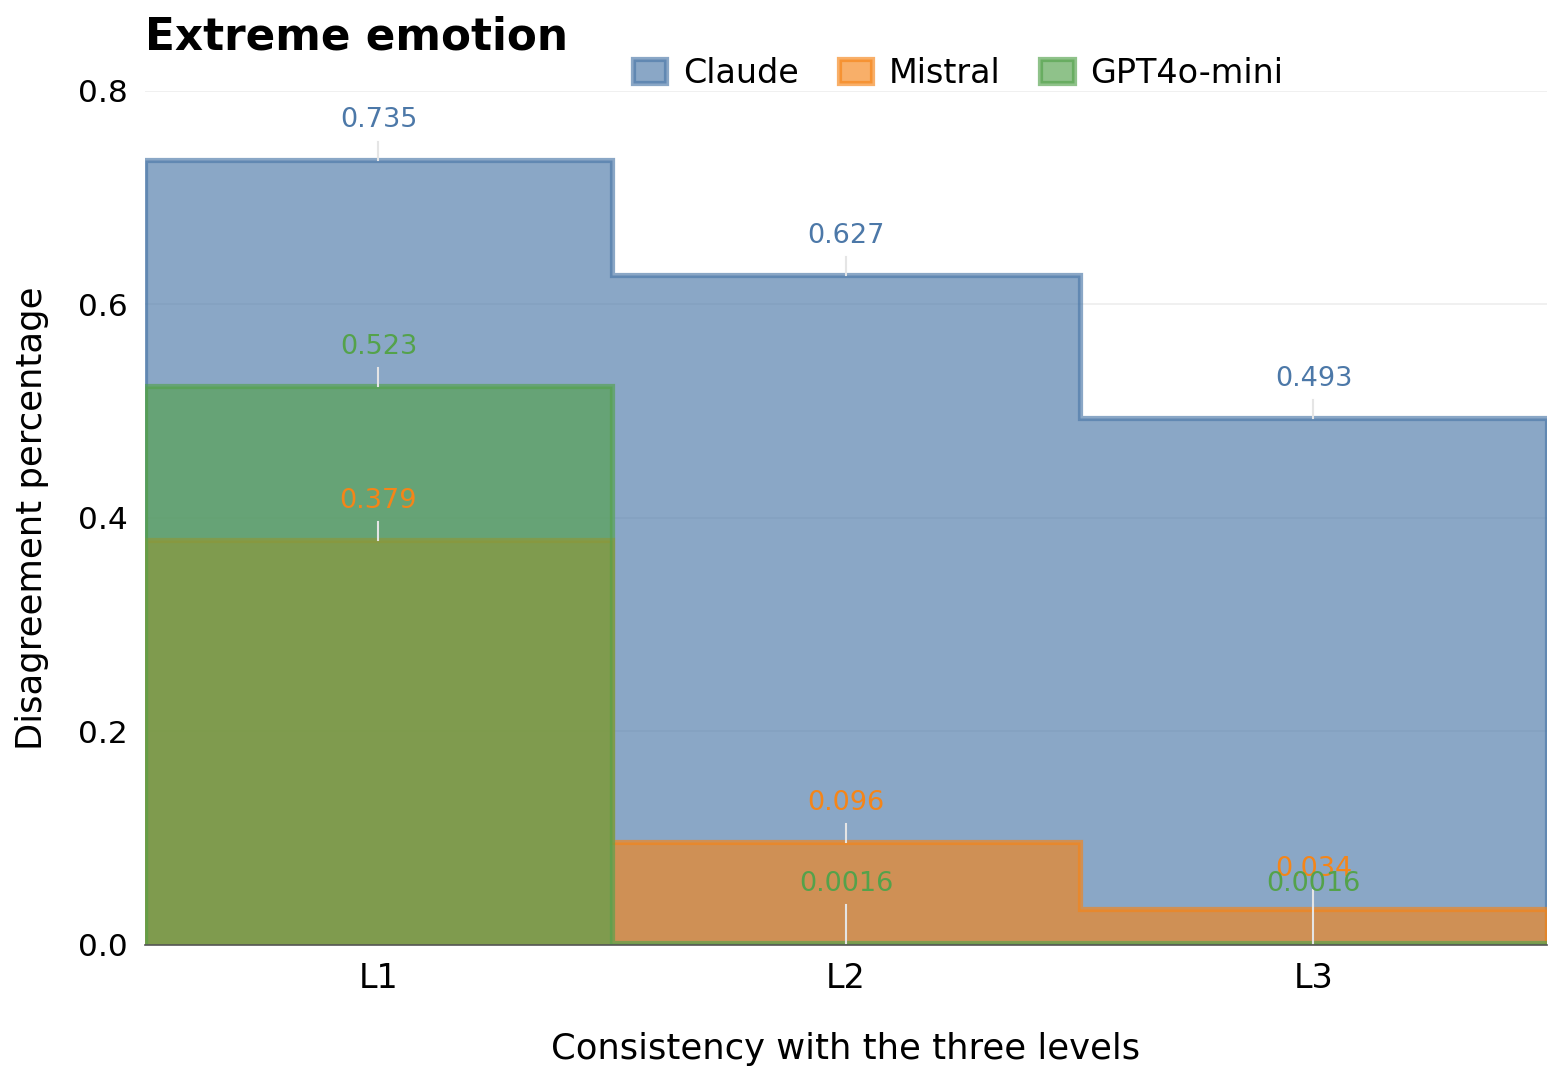

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

# =========================================================
# DATA
# =========================================================

levels = ["L1", "L2", "L3"]

claude = np.array([0.735, 0.627, 0.493])
mistral = np.array([0.379, 0.096, 0.034])
gpt4o = np.array([0.523, 0.0016, 0.0016])

x = np.arange(len(levels))

# =========================================================
# COLORS
# Muted, publication-friendly colors
# =========================================================

BLUE = "#4C78A8"      # muted blue,  4C78A8
ORANGE = "#F58518"    # muted orange, F58518
GREEN = "#54A24B"     # muted green, 54A24B

# Transparency of filled areas
FILL_ALPHA = 0.65 # 0.22

# =========================================================
# FIGURE
# =========================================================

fig, ax = plt.subplots(
    figsize=(11, 8.5),
    dpi=150
)

# =========================================================
# CATEGORY BOUNDARIES
#
# These ensure that L1 and L3 have the same width as L2.
#
#        L1        L2        L3
#      |---------|---------|---------|
#     -0.5       0.5       1.5       2.5
# =========================================================

edges = np.array([-0.5, 0.5, 1.5, 2.5])


# =========================================================
# CLAUDE
# =========================================================

ax.stairs(
    values=claude,
    edges=edges,
    baseline=0,
    fill=True,
    color=BLUE,
    alpha=FILL_ALPHA,
    linewidth=2.5,
    edgecolor=BLUE,
    label="Claude"
)

# =========================================================
# MISTRAL
# =========================================================

ax.stairs(
    values=mistral,
    edges=edges,
    baseline=0,
    fill=True,
    color=ORANGE,
    alpha=FILL_ALPHA,
    linewidth=2.5,
    edgecolor=ORANGE,
    label="Mistral"
)

# =========================================================
# GPT4o-mini
# =========================================================

ax.stairs(
    values=gpt4o,
    edges=edges,
    baseline=0,
    fill=True,
    color=GREEN,
    alpha=FILL_ALPHA,
    linewidth=2.5,
    edgecolor=GREEN,
    label="GPT4o-mini"
)

# =========================================================
# AXES
# =========================================================

ax.set_xlim(-0.5, 2.5)
ax.set_ylim(0, 0.8)

ax.set_xticks(x)
ax.set_xticklabels(
    levels,
    fontsize=16
)

ax.set_yticks(np.arange(0, 0.81, 0.2))
ax.set_yticklabels(
    [f"{v:.1f}" for v in np.arange(0, 0.81, 0.2)],
    fontsize=15
)

# =========================================================
# AXIS LABELS
# =========================================================

ax.set_xlabel(
    "Consistency with the three levels",
    fontsize=17,
    labelpad=18
)

ax.set_ylabel(
    "Disagreement percentage",
    fontsize=17,
    labelpad=14
)

# =========================================================
# GRIDLINES
# =========================================================

ax.grid(
    axis="y",
    color="#D9D9D9",
    linewidth=0.8,
    alpha=0.45
)

ax.set_axisbelow(True)

# =========================================================
# SPINES
# =========================================================

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.spines["bottom"].set_color("#555555")
ax.spines["bottom"].set_linewidth(0.8)

# Remove tick marks
ax.tick_params(
    axis="x",
    length=0,
    pad=8
)

ax.tick_params(
    axis="y",
    length=0,
    pad=8
)

# =========================================================
# TITLE
# =========================================================

ax.set_title(
    "Extreme emotion",
    fontsize=21,
    fontweight="bold",
    loc="left",
    pad=20
)

# =========================================================
# LEGEND
# =========================================================

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.58, 1.075),
    ncol=3,
    frameon=False,
    fontsize=16,
    handlelength=1.0,
    handletextpad=0.5,
    columnspacing=1.2
)

# =========================================================
# DATA LABELS
# =========================================================

# def add_label(xpos, value, color):

#     # Position of label
#     if value < 0.01:
#         y_label = 0.045
#     else:
#         y_label = value + 0.025

#     # Very light connector
#     ax.plot(
#         [xpos, xpos],
#         [value, y_label - 0.008],
#         color="#E5E5E5",
#         linewidth=1.0,
#         zorder=5
#     )

#     text = ax.text(
#         xpos,
#         y_label,
#         f"{value:g}",
#         ha="center",
#         va="bottom",
#         fontsize=13,
#         color=color,
#         zorder=10
#     )

#     # White outline makes labels readable over filled areas
#     text.set_path_effects([
#         pe.withStroke(
#             linewidth=3,
#             foreground="white"
#         )
#     ])

def add_label(xpos, value, color):

    # Position of label
    if value < 0.01:
        y_label = 0.045
    else:
        y_label = value + 0.025

    # Very light connector
    ax.plot(
        [xpos, xpos],
        [value, y_label - 0.008],
        color="#E5E5E5",
        linewidth=1.0,
        zorder=5
    )

    # Solid colored text — no white outline
    ax.text(
        xpos,
        y_label,
        f"{value:g}",
        ha="center",
        va="bottom",
        fontsize=13,
        color=color,
        fontweight="normal",
        zorder=10
    )


# Claude
for i, value in enumerate(claude):
    add_label(i, value, BLUE)

# Mistral
for i, value in enumerate(mistral):
    add_label(i, value, ORANGE)

# GPT4o-mini
for i, value in enumerate(gpt4o):
    add_label(i, value, GREEN)

# =========================================================
# LAYOUT
# =========================================================

plt.subplots_adjust(
    left=0.12,
    right=0.97,
    bottom=0.15,
    top=0.82
)

# =========================================================
# SAVE AS PDF
# =========================================================

plt.savefig(
    "Extreme_emotion_python.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

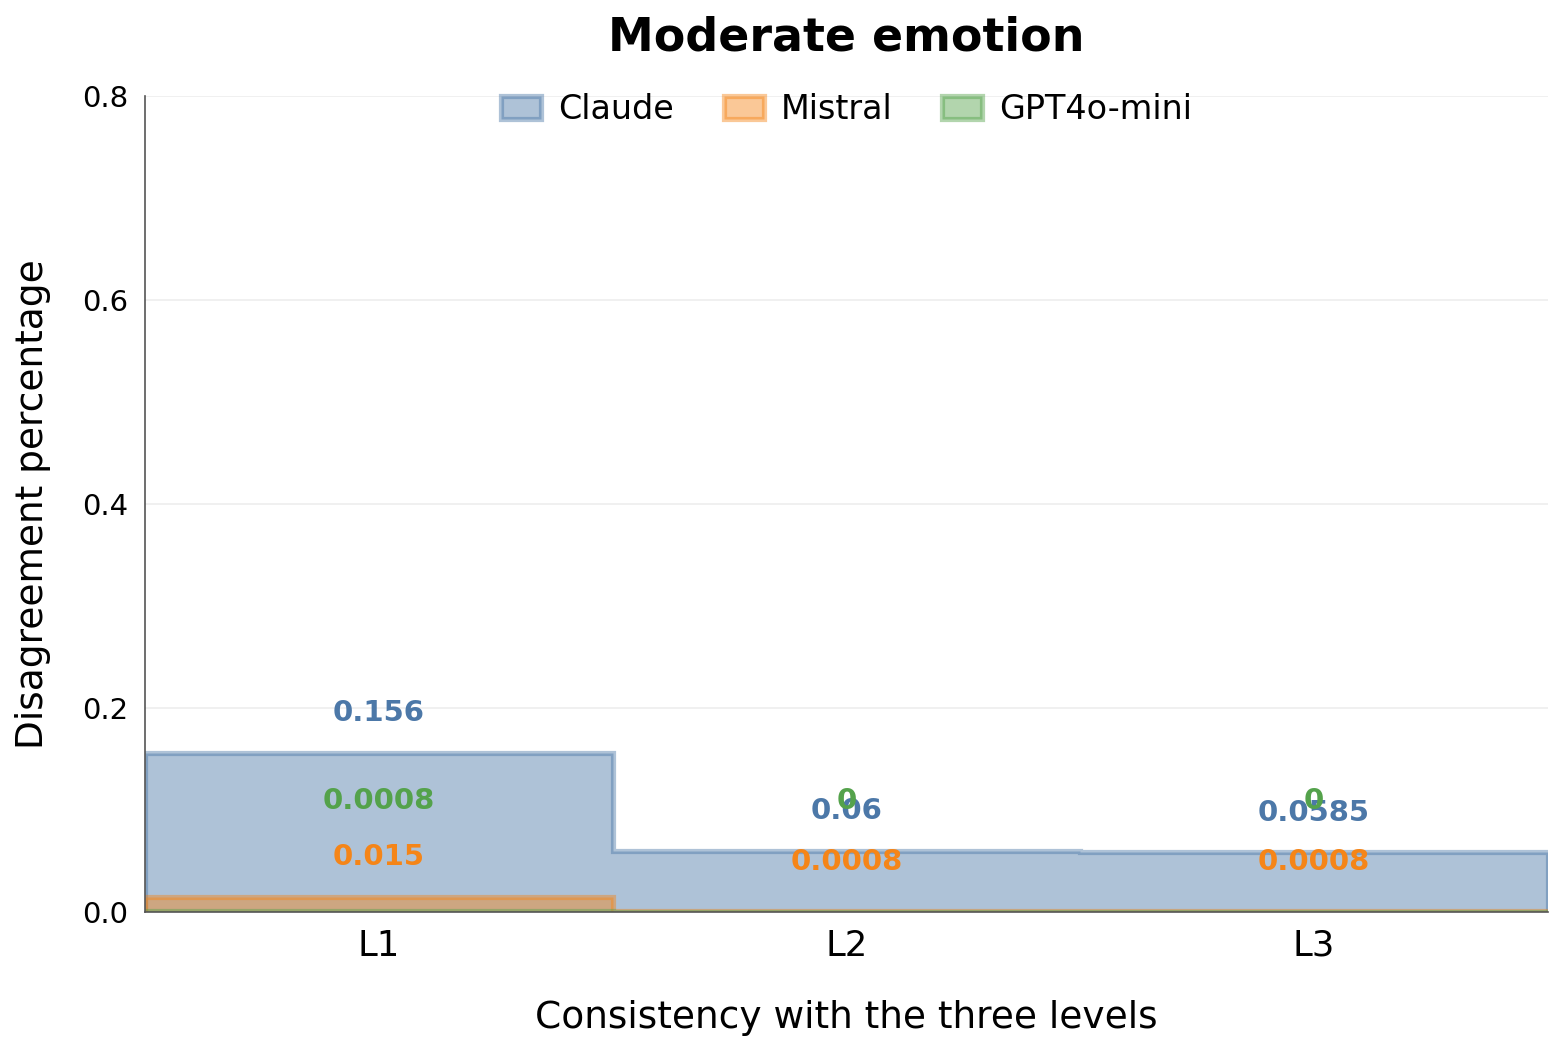

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# DATA
# =========================================================

levels = ["L1", "L2", "L3"]

claude = np.array([0.156, 0.06, 0.0585])  #3, 0.735, 0.627, 0.493
mistral = np.array([0.015, 0.0008, 0.0008])  #0.379, 0.096, 0.034
gpt4o = np.array([0.0008, 0.000, 0.000])   #0.523, 0.0016, 0.0016

x = np.arange(len(levels))

# =========================================================
# COLORS
# =========================================================

BLUE = "#4C78A8"
ORANGE = "#F58518"
GREEN = "#54A24B"

# More solid-looking fill
FILL_ALPHA = 0.45 #0.65

# =========================================================
# FIGURE
# =========================================================

fig, ax = plt.subplots(
    figsize=(11, 8),
    dpi=150
)

# =========================================================
# CATEGORY EDGES
#
# This makes L1, L2 and L3 equal-width regions.
# =========================================================

edges = np.array([-0.5, 0.5, 1.5, 2.5])

# =========================================================
# CLAUDE
# =========================================================

ax.stairs(
    claude,
    edges,
    baseline=0,
    fill=True,
    color=BLUE,
    alpha=FILL_ALPHA,
    linewidth=2.5,
    edgecolor=BLUE,
    label="Claude"
)

# =========================================================
# MISTRAL
# =========================================================

ax.stairs(
    mistral,
    edges,
    baseline=0,
    fill=True,
    color=ORANGE,
    alpha=FILL_ALPHA,
    linewidth=2.5,
    edgecolor=ORANGE,
    label="Mistral"
)

# =========================================================
# GPT4o-mini
# =========================================================

ax.stairs(
    gpt4o,
    edges,
    baseline=0,
    fill=True,
    color=GREEN,
    alpha=FILL_ALPHA,
    linewidth=2.5,
    edgecolor=GREEN,
    label="GPT4o-mini"
)

# =========================================================
# AXES LIMITS
# =========================================================

ax.set_xlim(-0.5, 2.5)
ax.set_ylim(0, 0.8)

# =========================================================
# X-AXIS
# =========================================================

ax.set_xticks(x)
ax.set_xticklabels(
    levels,
    fontsize=17
)

# =========================================================
# Y-AXIS
# =========================================================

yticks = np.arange(0, 0.81, 0.2)

ax.set_yticks(yticks)
ax.set_yticklabels(
    [f"{v:.1f}" for v in yticks],
    fontsize=14
)

# =========================================================
# AXIS LABELS
# =========================================================

ax.set_xlabel(
    "Consistency with the three levels",
    fontsize=18,
    labelpad=18
)

ax.set_ylabel(
    "Disagreement percentage",
    fontsize=18,
    labelpad=15
)

# =========================================================
# GRIDLINES
# =========================================================

ax.grid(
    axis="y",
    color="#D9D9D9",
    linewidth=0.8,
    alpha=0.45
)

ax.set_axisbelow(True)

# =========================================================
# SPINES
# =========================================================

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#555555")
ax.spines["left"].set_linewidth(0.8)

ax.spines["bottom"].set_color("#555555")
ax.spines["bottom"].set_linewidth(0.8)

# Remove tick marks
ax.tick_params(
    axis="x",
    length=0,
    pad=8
)

ax.tick_params(
    axis="y",
    length=0,
    pad=8
)

# =========================================================
# TITLE
# =========================================================

ax.set_title(
    "Moderate emotion",  #Extreme
    fontsize=22,
    fontweight="bold",
    loc="center",
    pad=22
)

# =========================================================
# LEGEND
# =========================================================

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.04),
    ncol=3,
    frameon=False,
    fontsize=16,
    handlelength=1.2,
    handletextpad=0.5,
    columnspacing=1.5
)

# =========================================================
# DATA LABELS
# =========================================================

# def add_label(xpos, value, color):

#     # Keep tiny values visible
#     if value < 0.01:
#         label_y = 0.045
#     else:
#         label_y = value + 0.025

#     ax.text(
#         xpos,
#         label_y,
#         f"{value:g}",
#         ha="center",
#         va="bottom",
#         fontsize=14,
#         color=color,
#         fontweight="bold"
#     )

# =========================================================
# DATA LABELS
# =========================================================

def add_label(xpos, value, color, model):

    # -----------------------------------------------------
    # Normal values
    # -----------------------------------------------------

    if value >= 0.01:

        label_y = value + 0.025

    # -----------------------------------------------------
    # Very small Mistral values
    # Keep them close to the baseline
    # -----------------------------------------------------

    elif model == "Mistral":

        label_y = 0.035

    # -----------------------------------------------------
    # Very small GPT4o-mini values
    # Place them higher to avoid overlap with Mistral
    # -----------------------------------------------------

    elif model == "GPT4o-mini":

        label_y = 0.095

    # -----------------------------------------------------
    # Label
    # -----------------------------------------------------

    ax.text(
        xpos,
        label_y,
        f"{value:g}",
        ha="center",
        va="bottom",
        fontsize=14,
        color=color,
        fontweight="bold"
    )


# =========================================================
# Claude labels
# =========================================================

for i, value in enumerate(claude):
    add_label(
        i,
        value,
        BLUE,
        "Claude"
    )


# =========================================================
# Mistral labels
# =========================================================

for i, value in enumerate(mistral):
    add_label(
        i,
        value,
        ORANGE,
        "Mistral"
    )


# =========================================================
# GPT4o-mini labels
# =========================================================

for i, value in enumerate(gpt4o):
    add_label(
        i,
        value,
        GREEN,
        "GPT4o-mini"
    )


# =========================================================
# LAYOUT
# =========================================================

plt.subplots_adjust(
    left=0.12,
    right=0.97,
    bottom=0.14,
    top=0.82
)

# =========================================================
# SAVE AS PDF
# =========================================================

plt.savefig(
    "Moderate_emotion_python.pdf",  #Extreme
    format="pdf",
    bbox_inches="tight"
)

# Display
plt.show()


# # Claude labels
# for i, value in enumerate(claude):
#     add_label(i, value, BLUE)

# # Mistral labels
# for i, value in enumerate(mistral):
#     add_label(i, value, ORANGE)

# # GPT4o-mini labels
# for i, value in enumerate(gpt4o):
#     add_label(i, value, GREEN)

# =========================================================
# LAYOUT
# =========================================================

# plt.subplots_adjust(
#     left=0.12,
#     right=0.97,
#     bottom=0.14,
#     top=0.82
# )

# # =========================================================
# # SAVE AS PDF
# # =========================================================

# plt.savefig(
#     "Moderate_emotion_python.pdf",  #Extreme
#     format="pdf",
#     bbox_inches="tight"
# )

# # Display
# plt.show()

In [ ]:
# =========================================================
# DATA LABELS
# =========================================================

def add_label(xpos, value, color, model):

    # -----------------------------------------------------
    # Normal values
    # -----------------------------------------------------

    if value >= 0.01:

        label_y = value + 0.025

    # -----------------------------------------------------
    # Very small Mistral values
    # Keep them close to the baseline
    # -----------------------------------------------------

    elif model == "Mistral":

        label_y = 0.035

    # -----------------------------------------------------
    # Very small GPT4o-mini values
    # Place them higher to avoid overlap with Mistral
    # -----------------------------------------------------

    elif model == "GPT4o-mini":

        label_y = 0.095

    # -----------------------------------------------------
    # Label
    # -----------------------------------------------------

    ax.text(
        xpos,
        label_y,
        f"{value:g}",
        ha="center",
        va="bottom",
        fontsize=14,
        color=color,
        fontweight="bold"
    )


# =========================================================
# Claude labels
# =========================================================

for i, value in enumerate(claude):
    add_label(
        i,
        value,
        BLUE,
        "Claude"
    )


# =========================================================
# Mistral labels
# =========================================================

for i, value in enumerate(mistral):
    add_label(
        i,
        value,
        ORANGE,
        "Mistral"
    )


# =========================================================
# GPT4o-mini labels
# =========================================================

for i, value in enumerate(gpt4o):
    add_label(
        i,
        value,
        GREEN,
        "GPT4o-mini"
    )


# =========================================================
# LAYOUT
# =========================================================

plt.subplots_adjust(
    left=0.12,
    right=0.97,
    bottom=0.14,
    top=0.82
)

# =========================================================
# SAVE AS PDF
# =========================================================

plt.savefig(
    "Moderate_emotion_python.pdf",  #Extreme
    format="pdf",
    bbox_inches="tight"
)

# Display
plt.show()

<Figure size 640x480 with 0 Axes>

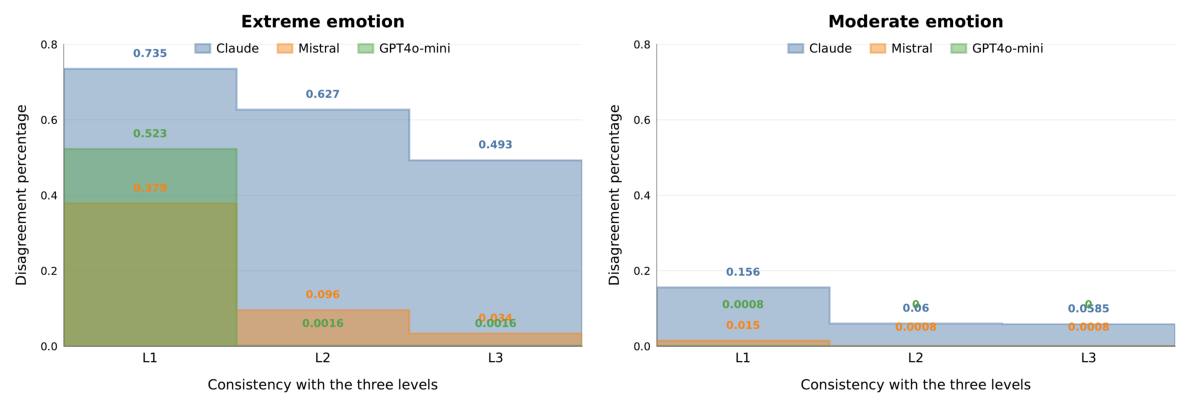

In [ ]:
import matplotlib.pyplot as plt
from pdf2image import convert_from_path

# 1. Define the paths to your 2 PDF files
pdf_paths = [
    "Extreme_emotion_python__.pdf",  #Hindi-_ Marathi(BERT-based), Hindi_Marathi(Random), Claude3.5haiku_actual
    "Moderate_emotion_python.pdf"  #Marathi_Hindi(BERT-based), Marathi-_ Hindi(Random), GPT4omini_actual
]

# 2. Set up the matplotlib figure with 1 row and 2 columns
# figsize=(width, height) in inches. 12x6 or 10x5 works well for two standard pages.
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# 3. Loop through the PDFs and plot them side-by-side
for i, pdf_path in enumerate(pdf_paths):
    try:
        # Convert the first page of the PDF into an image
        images = convert_from_path(pdf_path, first_page=1, last_page=1)

        if images:
            # Display the image on the corresponding subplot axis
            axes[i].imshow(images[0])
            # axes[i].set_title(f"Plot {i+1}", fontsize=12)

    except Exception as e:
        axes[i].text(0.5, 0.5, f"Error loading\n{pdf_path}",
                     ha='center', va='center', color='red')
        print(f"Error processing {pdf_path}: {e}")

    # Hide the x/y axis ticks for a cleaner look
    axes[i].axis('off')

# 4. Optimize layout and show the result
plt.tight_layout()

# Pro-Tip: If there is too much horizontal space between the two plots,
# you can use wspace (width space) to bring them closer together:
# plt.subplots_adjust(wspace=0.05)
plt.savefig("ResultsPercent.pdf", dpi=300)
plt.show()

In [ ]:
l = []
a = ['s', 'cf', 'ab']
b = ['bh', 'od']

In [ ]:
l.append(b)

In [ ]:
l

[['s', 'cf', 'ab'], ['bh', 'od']]

In [ ]:
!pip install fitz
# !pip uninstall fitz

  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


In [ ]:
!pip install tools

In [ ]:
!pip install reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 34.7 MB/s eta 0:00:00


In [ ]:
!pip install PyPDF2.Transformation

ERROR: Could not find a version that satisfies the requirement PyPDF2.Transformation (from versions: none)
ERROR: No matching distribution found for PyPDF2.Transformation


In [ ]:
!pip install PyPDF2

In [ ]:
!pip install pymupdf #related to fitz, pip install pymupdf
# !pip uninstall pymupdf


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 53.7 MB/s eta 0:00:00


In [ ]:
!pip install pillow

In [ ]:
!apt-get install poppler-utils

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  poppler-utils
0 upgraded, 1 newly installed, 0 to remove and 24 not upgraded.
Need to get 186 kB of archives.
After this operation, 697 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy-updates/main amd64 poppler-utils amd64 22.02.0-2ubuntu0.13 [186 kB]
Fetched 186 kB in 1s (308 kB/s)
Selecting previously unselected package poppler-utils.
(Reading database ... 118332 files and directories currently installed.)
Preparing to unpack .../poppler-utils_22.02.0-2ubuntu0.13_amd64.deb ...
Unpacking poppler-utils (22.02.0-2ubuntu0.13) ...
Setting up poppler-utils (22.02.0-2ubuntu0.13) ...
Processing triggers for man-db (2.10.2-1) ...


In [ ]:
!pip install pdf2image #matplotlib